# Business Understanding

ShopSphere also faces difficulty accurately predicting customer spending and long-term value,
limiting its ability to plan revenue strategies and personalise pricing decisions. This task
addresses the business need to **forecast each customer's Lifetime Value**, so that marketing
and retention resources can be allocated toward the customers most likely to generate long-term
revenue, rather than treating all customers identically.

**Objective:** build and compare multiple regression models to predict `Lifetime_Value` from
customer demographic, engagement, and transaction behaviour data, and use the
best-performing model's predictions to segment customers into value tiers for targeted pricing
and retention decisions.

**Success criteria:** a model that minimises prediction error (low RMSE and MAE) while explaining
a high proportion of the variation in customer value (high R²), with performance validated on
unseen test data to ensure the model generalises reliably rather than overfitting to historical
patterns.

# ***Task 1***


---



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Below code is written to make sure that everytime it is run the results are the same
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1. Loading the dataset

In [ ]:
# Loading the dataset
dataset = "ecommerce_customer_churn_dataset.csv"
df = pd.read_csv(dataset)

print("Shape: ", df.shape)
print("\nInformation:\n")
df.info()
print("\nFirst 5 rows:\n", df.head())

Shape:  (50000, 25)

Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  object 
 2   Country                        50000 non-null  object 
 3   City                           50000 non-null  object 
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  float64
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_

### Exploratory Data Analysis (EDA)

                 Age  Gender Country     City  Membership_Years  \
count   47505.000000   50000   50000    50000      50000.000000   
unique           NaN       3       8       40               NaN   
top              NaN  Female     USA  Houston               NaN   
freq             NaN   25116   17384     3549               NaN   
mean       37.802968     NaN     NaN      NaN          2.984009   
std        11.834668     NaN     NaN      NaN          2.059105   
min         5.000000     NaN     NaN      NaN          0.100000   
25%        29.000000     NaN     NaN      NaN          1.400000   
50%        38.000000     NaN     NaN      NaN          2.500000   
75%        46.000000     NaN     NaN      NaN          4.000000   
max       200.000000     NaN     NaN      NaN         10.000000   

        Login_Frequency  Session_Duration_Avg  Pages_Per_Session  \
count      50000.000000          46601.000000       47000.000000   
unique              NaN                   NaN              

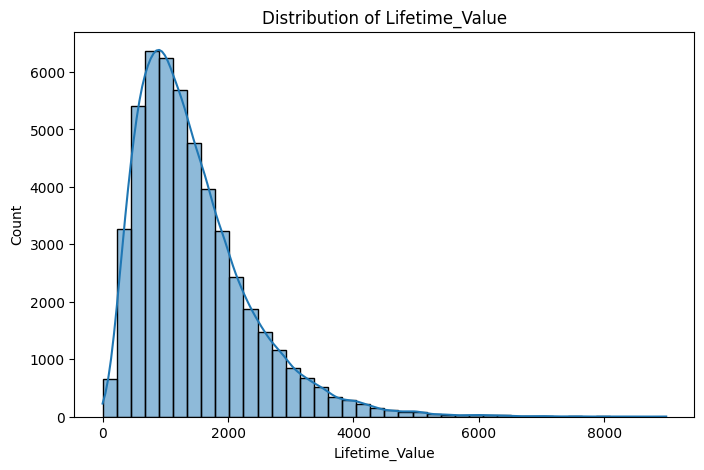

In [ ]:
# Summary statistics
print(df.describe(include="all"))

# Check missing values
print("\nMissing values per column:\n", df.isnull().sum())

# Distribution of the regression target
plt.figure(figsize=(8, 5))
sns.histplot(df["Lifetime_Value"], bins=40, kde=True)
plt.title("Distribution of Lifetime_Value")
plt.show()

In [ ]:
# Separate numerical columns and categorical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

Total_Purchases                  0.622778
Session_Duration_Avg             0.553446
Pages_Per_Session                0.532007
Mobile_App_Usage                 0.527574
Login_Frequency                  0.499324
Wishlist_Items                   0.477359
Email_Open_Rate                  0.467149
Social_Media_Engagement_Score    0.462303
Product_Reviews_Written          0.435825
Credit_Balance                   0.401191
Average_Order_Value              0.151574
Days_Since_Last_Purchase         0.006718
Payment_Method_Diversity         0.006045
Membership_Years                 0.003583
Returns_Rate                     0.002133
Discount_Usage_Rate              0.000799
Age                             -0.001445
Churned                         -0.010684
Customer_Service_Calls          -0.295334
Cart_Abandonment_Rate           -0.495295
Name: Lifetime_Value, dtype: float64


/tmp/ipykernel_817/4009042246.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_ltv.index, y=corr_ltv.values, palette='viridis')


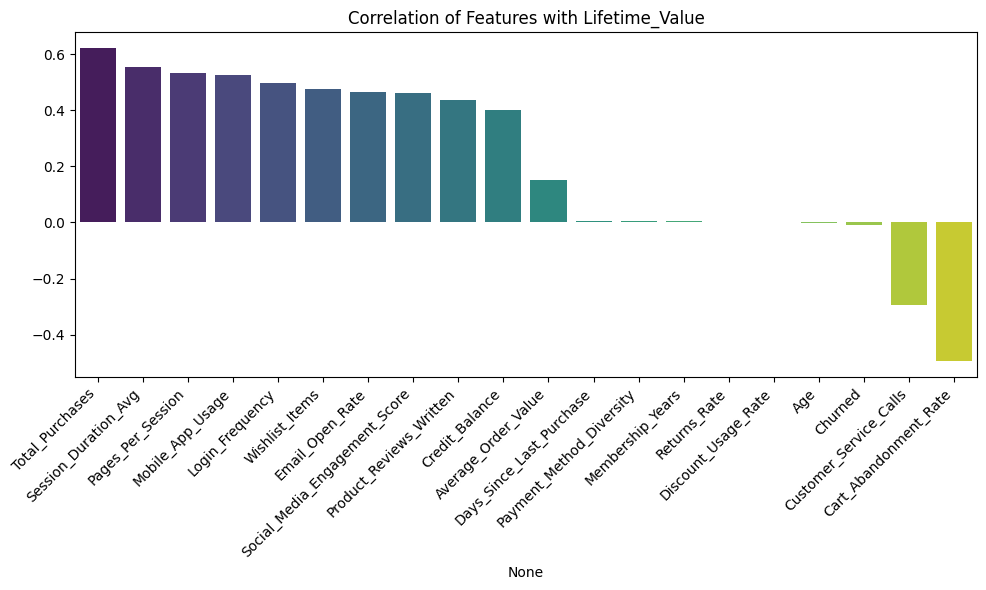

In [ ]:
# Correlation of numeric features with the target
corr_ltv = df[num_cols].corr()["Lifetime_Value"].drop("Lifetime_Value").sort_values(ascending=False)
print(corr_ltv)

plt.figure(figsize=(10, 6))
sns.barplot(x=corr_ltv.index, y=corr_ltv.values, palette='viridis')
plt.title("Correlation of Features with Lifetime_Value")
plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()

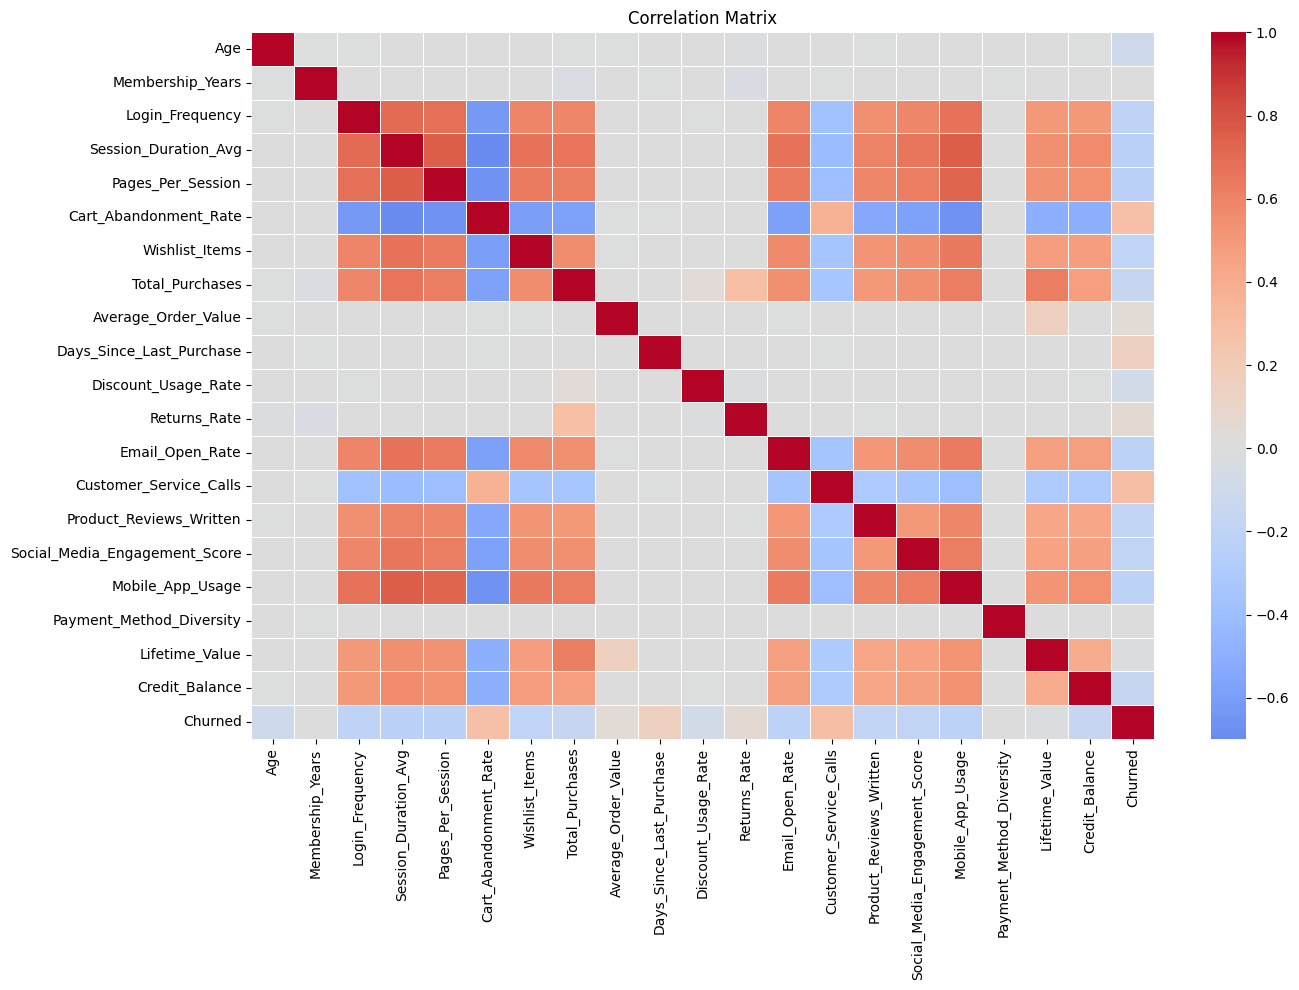

In [ ]:
# Correlation between the features themselves - pairs above 0.8 are redundant

plt.figure(figsize=(14, 10))
sns.heatmap(df[num_cols].corr(), cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Sanity check: is Lifetime_Value roughly reconstructable from a simple
# combination of purchase features? If so, high R² would reflect a
# near-formulaic relationship rather than a discovered pattern.

print("Correlation of individual features with Lifetime_Value:")
print(df[["Average_Order_Value", "Total_Purchases", "Credit_Balance",
          "Membership_Years", "Lifetime_Value"]].corr()["Lifetime_Value"].sort_values(ascending=False))

# Does Average_Order_Value x Total_Purchases approximate Lifetime_Value?
implied_value = df["Average_Order_Value"] * df["Total_Purchases"]
print("\nCorrelation of (Average_Order_Value x Total_Purchases) with Lifetime_Value:",
      round(implied_value.corr(df["Lifetime_Value"]), 4))

Correlation of individual features with Lifetime_Value:
Lifetime_Value         1.000000
Total_Purchases        0.622778
Credit_Balance         0.401191
Average_Order_Value    0.151574
Membership_Years       0.003583
Name: Lifetime_Value, dtype: float64

Correlation of (Average_Order_Value x Total_Purchases) with Lifetime_Value: 0.3192


### 2. Handling Duplicate Rows


In [ ]:
# Check for duplicate rows
print("Number of duplicate rows: ", df.duplicated().sum())

#Remove duplicates if any exist
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates: ", df.shape)

Number of duplicate rows:  0
Shape after removing duplicates:  (50000, 25)


### 3. Handling Logically invalid values


In [ ]:
# Check for logically invalid values

print("Invalid Age values:", (df["Age"] < 18).sum() + (df["Age"] > 100).sum())
print("Negative Total Purchases:", (df["Total_Purchases"] < 0).sum())
print("Cart Abandonment Rate > 100:", (df["Cart_Abandonment_Rate"] > 100).sum())
print("Discount Usage Rate > 100:", (df["Discount_Usage_Rate"] > 100).sum())
print("Returns Rate > 100:", (df["Returns_Rate"] > 100).sum())
print("Email Open Rate > 100:", (df["Email_Open_Rate"] > 100).sum())
print("Social Media Engagement > 100:", (df["Social_Media_Engagement_Score"] > 100).sum())

Invalid Age values: 50
Negative Total Purchases: 40
Cart Abandonment Rate > 100: 30
Discount Usage Rate > 100: 207
Returns Rate > 100: 0
Email Open Rate > 100: 0
Social Media Engagement > 100: 0


In [ ]:
# Correct logically invalid values by clipping to each variable's valid domain.
# Unlike the IQR outliers above, these bounds come from the variable's own
# definition (a rate cannot exceed 100%, a purchase count cannot be negative),
# not from any statistic computed over the data - so this is safe to apply
# before the train/test split without any leakage risk.

invalid_before = {
    "Age (<18 or >100)": ((df["Age"] < 18) | (df["Age"] > 100)).sum(),
    "Total_Purchases (<0)": (df["Total_Purchases"] < 0).sum(),
    "Cart_Abandonment_Rate (>100)": (df["Cart_Abandonment_Rate"] > 100).sum(),
    "Discount_Usage_Rate (>100)": (df["Discount_Usage_Rate"] > 100).sum(),
}

df["Age"] = df["Age"].clip(lower=18, upper=100)
df["Total_Purchases"] = df["Total_Purchases"].clip(lower=0)
df["Cart_Abandonment_Rate"] = df["Cart_Abandonment_Rate"].clip(upper=100)
df["Discount_Usage_Rate"] = df["Discount_Usage_Rate"].clip(upper=100)

print("Rows corrected:")
for label, count in invalid_before.items():
    print(f"  {label}: {count}")

print("\nInvalid values remaining after clipping:")
print("Invalid Age:", ((df["Age"] < 18) | (df["Age"] > 100)).sum())
print("Negative Total Purchases:", (df["Total_Purchases"] < 0).sum())
print("Cart Abandonment Rate > 100:", (df["Cart_Abandonment_Rate"] > 100).sum())
print("Discount Usage Rate > 100:", (df["Discount_Usage_Rate"] > 100).sum())

Rows corrected:
  Age (<18 or >100): 50
  Total_Purchases (<0): 40
  Cart_Abandonment_Rate (>100): 30
  Discount_Usage_Rate (>100): 207

Invalid values remaining after clipping:
Invalid Age: 0
Negative Total Purchases: 0
Cart Abandonment Rate > 100: 0
Discount Usage Rate > 100: 0


### 4. Feature Engineering

In [ ]:
# Feature Engineering

df["Engagement_Score"] = (df["Login_Frequency"] + df["Session_Duration_Avg"]+ df["Pages_Per_Session"] + df["Mobile_App_Usage"] + df["Social_Media_Engagement_Score"])
df["Purchase_Activity"] = df["Total_Purchases"] / (df["Membership_Years"] + 1)
df["Risk_Score"] = (df["Cart_Abandonment_Rate"] + df["Returns_Rate"] + df["Customer_Service_Calls"] + df["Discount_Usage_Rate"])
df["Friction_Index"] = (df["Cart_Abandonment_Rate"] + df["Returns_Rate"] + df["Customer_Service_Calls"])

### 5. Splitting Train and Test Data

In [ ]:
# Task 3 input features (per the assignment brief), plus the same engineered
# features used in Task 2, for consistency across the two notebooks.
X = df[["Age", "Gender", "Membership_Years", "Login_Frequency",
        "Session_Duration_Avg", "Cart_Abandonment_Rate", "Mobile_App_Usage",
        "Social_Media_Engagement_Score", "Total_Purchases", "Average_Order_Value",
        "Days_Since_Last_Purchase", "Discount_Usage_Rate", "Returns_Rate",
        "Customer_Service_Calls", "Credit_Balance", "Engagement_Score",
        "Purchase_Activity", "Risk_Score"]]
y = df["Lifetime_Value"]

# Train - Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 40000
Testing Samples: 10000


**Data partitioning strategy**

The dataset is split 80/20 into 40,000 training and 10,000 test customers (random_state=42). The target, Lifetime_Value, is continuous, so the split is not stratified. Hyperparameters are selected by 5-fold cross-validation within the training set: in each fold the model is fitted on 32,000 customers and validated on the remaining 8,000, so every training customer serves as validation data exactly once. The standard deviation across folds shows whether an apparent difference between settings is larger than the natural variation between samples, and several tuning decisions in this notebook turned out to be within that variation.

The test set is used for the final evaluation of each model, and no preprocessing statistic (imputation value or scaling parameter) is calculated from it. Two diagnostic comparisons (Random Forest depth and Gradient Boosting configuration) also inspected test scores; in both cases the choice rests on the cross-validation results, as explained where they appear.



### 6. Handling Missing Values

In [ ]:
# after train_test_split
X_train = X_train.copy()
X_test  = X_test.copy()

for col in X_train.select_dtypes(include=['int64', 'float64']).columns:
    median_value = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_value)
    X_test[col]  = X_test[col].fillna(median_value) # same median of x_train

for col in X_train.select_dtypes(include='object').columns:
    mode_value = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode_value)
    X_test[col]  = X_test[col].fillna(mode_value) # same mode of x_train

print("Missing values after imputation  - train:", X_train.isnull().sum().sum(),
      "| test:", X_test.isnull().sum().sum())

Missing values after imputation  - train: 0 | test: 0


**Why median for numeric columns, and mode for categorical columns**

Median was chosen over mean for numeric imputation because several features in this dataset are
right-skewed rather than symmetric (confirmed later in the outlier analysis - `Purchase_Activity`,
`Returns_Rate`, and originally `Average_Order_Value` all showed high skew). The mean is pulled
toward extreme values in a skewed distribution, so a handful of very high spenders can drag the
*mean* purchase amount well above what a typical customer actually looks like. The median, being
the middle value regardless of how stretched the tail is, represents a realistic, typical
customer rather than a value distorted by outliers. Since outliers were deliberately retained
elsewhere in this pipeline rather than removed (justifying the use of `RobustScaler` in the
scaling step), using the median for imputation is the consistent choice - both decisions rest on
the same principle: don't let extreme values distort the estimate of "normal."

Mode was used for categorical columns because mean and median are mathematical concepts that only
apply to numbers - there is no meaningful "average" of category labels like `Male` and `Female`.
Mode (the most frequently occurring category) is the natural equivalent: it fills a missing value
with whatever category is already most common in the training data, the least assumption-laden
guess available without further information about that specific customer.

Both choices follow the same underlying principle - impute with whatever value is most
representative of the *typical* case, using whichever measure of "typical" is mathematically
appropriate for that column's data type - and in both cases, the median/mode is calculated from
the training set only (`X_train`), never the test set, to avoid leaking test-set information into
the imputation step.

### 7. Handling Outliers

Outliers are data values that are explicitly higher or lower than usual values in a dataset, which can cause skewing of statistical results. Interquartile Range (IQR) is a measure of statistical dispersion that tells how spread out the middle 50% of the data is.

How IQR works:


*   Q1 (First Quartile) - The value at the 25th percentile.
*   Q3 (Third Quartile) - The value at the 75th percentile.
*   IQR = Q3 - Q1





In [ ]:
# Check for outliers using IQR method - computed on X_train only,
# so the test set plays no role in this decision, consistent with
# how missing values were handled above.

num_cols_train = X_train.select_dtypes(include=['int64', 'float64']).columns
outlier_summary = []

for col in num_cols_train:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    outlier_summary.append({
        "Column": col, "Outliers": outliers,
        "Outlier %": round((outliers / len(X_train)) * 100, 2),
        "Skew": round(X_train[col].skew(), 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
print(outlier_df.sort_values("Outliers", ascending=False).to_string(index=False))

                       Column  Outliers  Outlier %  Skew
             Engagement_Score      3035       7.59  0.79
     Days_Since_Last_Purchase      2192       5.48  2.08
            Purchase_Activity      1885       4.71  7.58
                 Returns_Rate      1383       3.46  6.15
             Membership_Years      1127       2.82  1.13
       Customer_Service_Calls       961       2.40  0.45
                   Risk_Score       934       2.34  0.18
          Average_Order_Value       789       1.97 42.95
             Mobile_App_Usage       604       1.51  0.46
Social_Media_Engagement_Score       569       1.42  0.57
              Total_Purchases       477       1.19  2.67
               Credit_Balance       468       1.17  0.42
         Session_Duration_Avg       427       1.07  0.44
              Login_Frequency       259       0.65  0.52
                          Age       249       0.62  0.30
        Cart_Abandonment_Rate       243       0.61 -0.29
          Discount_Usage_Rate  

In [ ]:
# Check the statistical distribution of numerical features (X_train only)

print("Numerical Feature Statistics:")
display(X_train[num_cols_train].describe().T)

Numerical Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
Age,40000.0,37.802225,11.266436,18.00,30.0000,38.000000,45.00000,100.000000
Membership_Years,40000.0,2.988913,2.061011,0.10,1.4000,2.500000,4.10000,10.000000
Login_Frequency,40000.0,11.626375,7.817759,0.00,6.0000,11.000000,17.00000,46.000000
Session_Duration_Avg,40000.0,27.594047,10.495941,1.00,20.2000,26.700000,34.00000,75.600000
Cart_Abandonment_Rate,40000.0,57.064530,16.280083,0.00,46.4000,58.100000,68.70000,100.000000
Mobile_App_Usage,40000.0,19.289770,8.924778,0.00,13.2000,18.600000,24.50000,61.900000
Social_Media_Engagement_Score,40000.0,29.181303,19.293887,0.00,15.4000,27.700000,40.60000,100.000000
Total_Purchases,40000.0,13.110290,6.975117,0.00,8.0000,12.000000,17.00000,128.700000
Average_Order_Value,40000.0,122.954556,173.846667,26.38,87.0575,112.915000,144.46000,9666.379178
Days_Since_Last_Purchase,40000.0,29.331850,28.838560,0.00,9.0000,21.000000,39.00000,283.000000


In [ ]:
# Check number of unique values, minimum and maximum values (X_train only)

for col in num_cols_train:
  print("==== ", col, " ====")
  print("Unique Values: ", X_train[col].nunique())
  print("Minimum: ", X_train[col].min())
  print("Maximum: ", X_train[col].max())

====  Age  ====
Unique Values:  59
Minimum:  18.0
Maximum:  100.0
====  Membership_Years  ====
Unique Values:  179
Minimum:  0.1
Maximum:  10.0
====  Login_Frequency  ====
Unique Values:  45
Minimum:  0.0
Maximum:  46.0
====  Session_Duration_Avg  ====
Unique Values:  651
Minimum:  1.0
Maximum:  75.6
====  Cart_Abandonment_Rate  ====
Unique Values:  965
Minimum:  0.0
Maximum:  100.0
====  Mobile_App_Usage  ====
Unique Values:  535
Minimum:  0.0
Maximum:  61.9
====  Social_Media_Engagement_Score  ====
Unique Values:  958
Minimum:  0.0
Maximum:  100.0
====  Total_Purchases  ====
Unique Values:  123
Minimum:  0.0
Maximum:  128.70000000000002
====  Average_Order_Value  ====
Unique Values:  15265
Minimum:  26.38
Maximum:  9666.37917838422
====  Days_Since_Last_Purchase  ====
Unique Values:  231
Minimum:  0.0
Maximum:  283.0
====  Discount_Usage_Rate  ====
Unique Values:  1627
Minimum:  0.3
Maximum:  100.0
====  Returns_Rate  ====
Unique Values:  371
Minimum:  0.0
Maximum:  99.6157338622138


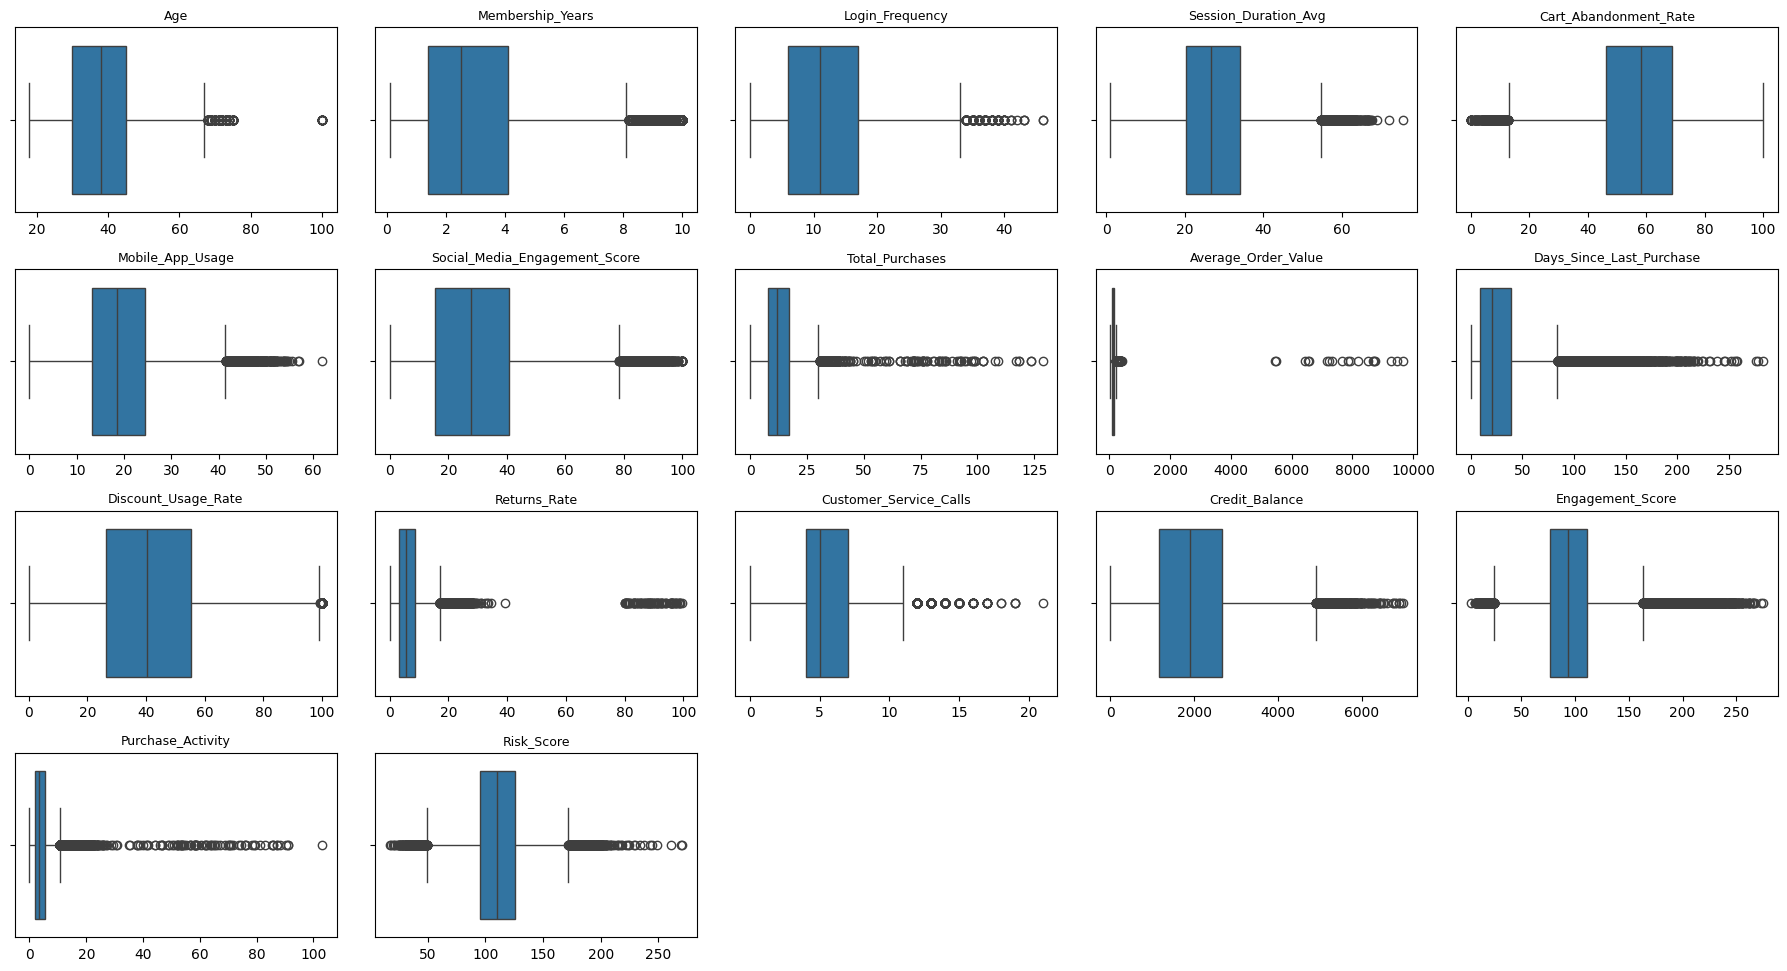

In [ ]:
# Visualize the numerical features using boxplots (X_train only)

plt.figure(figsize=(18, 12))
for i, col in enumerate(num_cols_train, 1):
    plt.subplot(5, 5, i)
    sns.boxplot(x=X_train[col])
    plt.title(col, fontsize=9)
    plt.xlabel("")
plt.tight_layout()
plt.show()

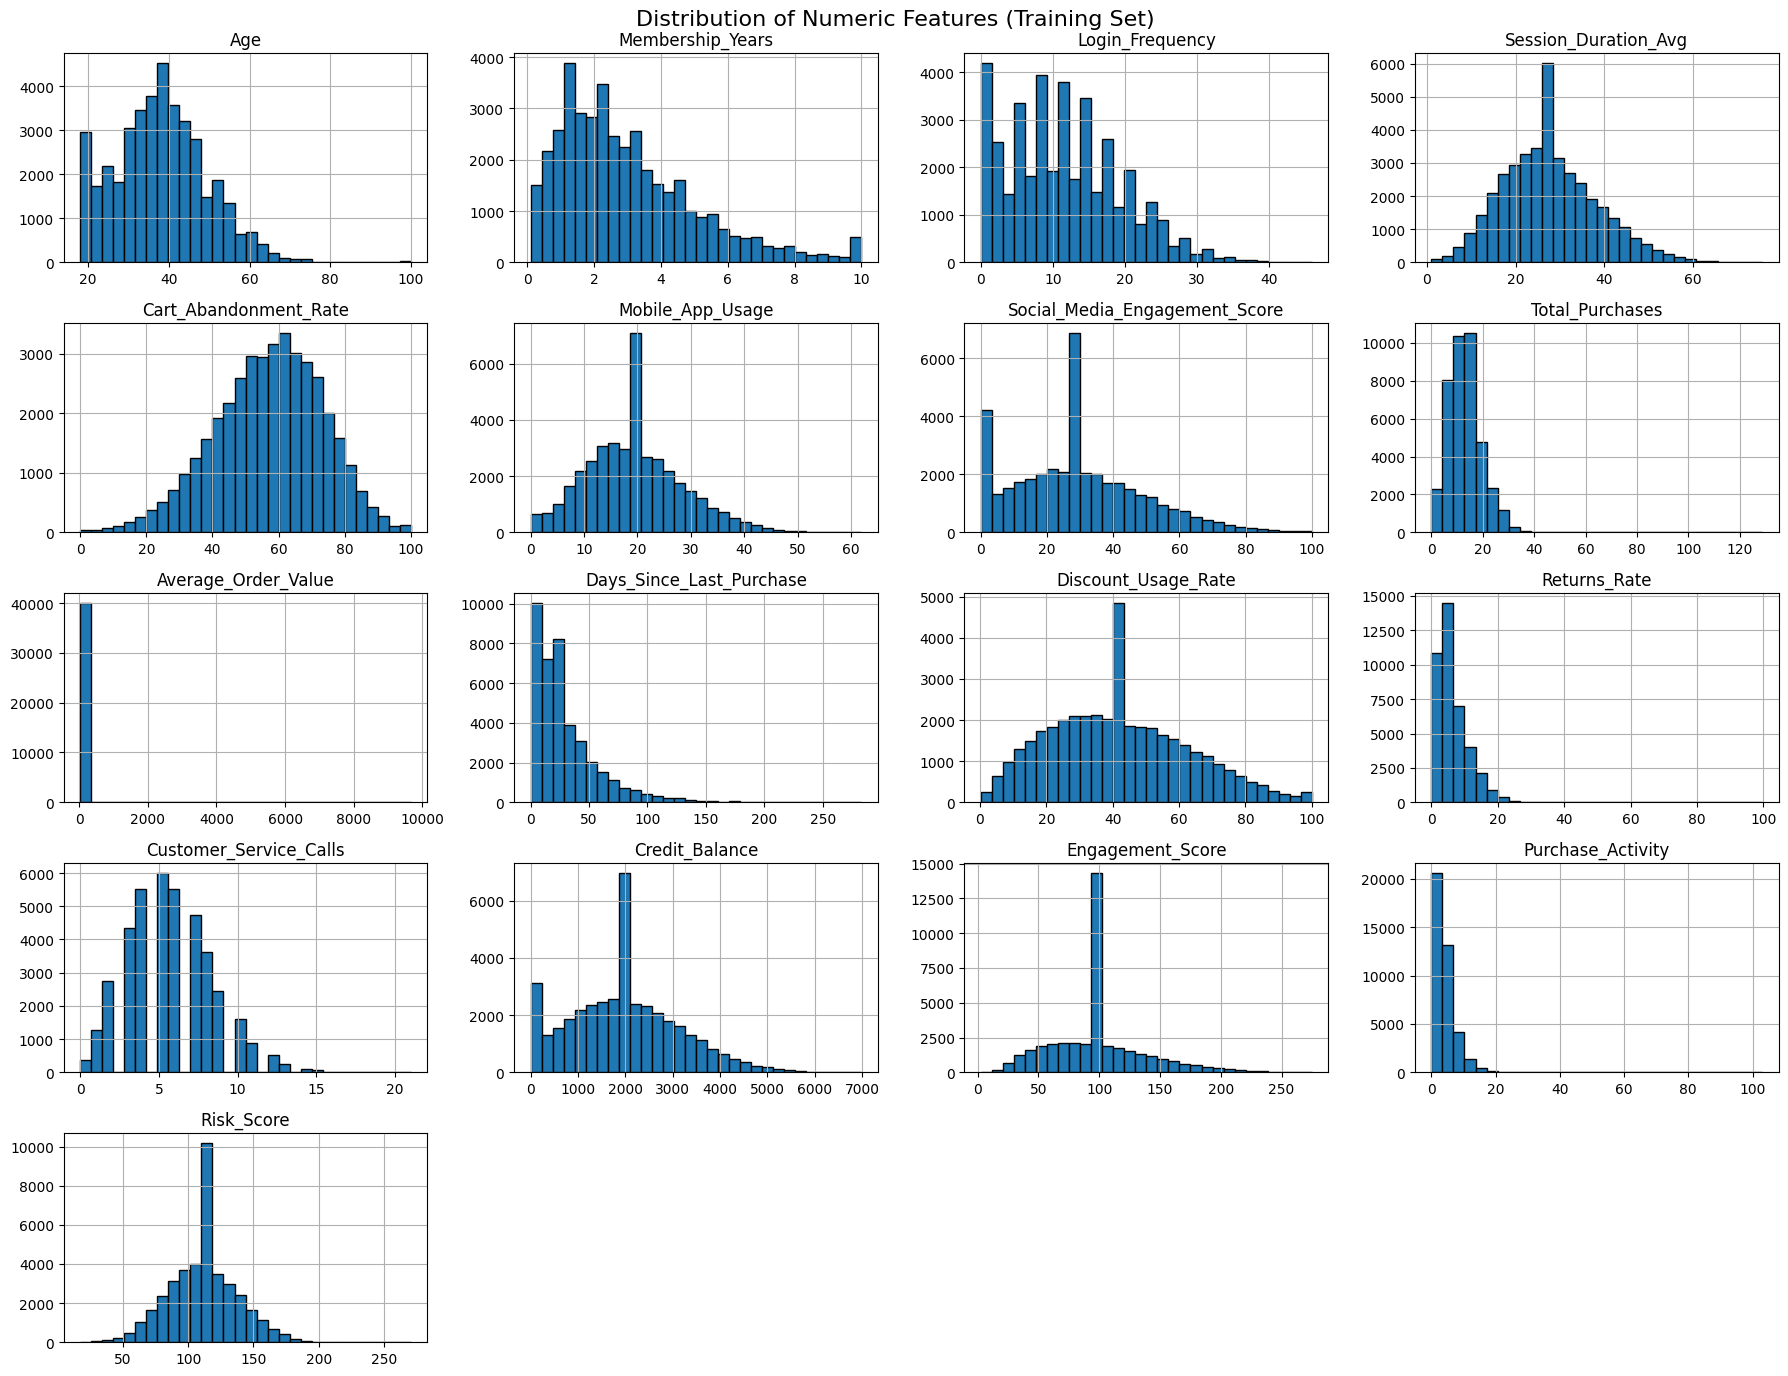

In [ ]:
# Distribution of every numeric feature (X_train only)

X_train[num_cols_train].hist(bins=30, figsize=(18, 14), edgecolor='black')
plt.suptitle("Distribution of Numeric Features (Training Set)", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# Display the actual invalid records (before clipping)

invalid_data = df[
    (df["Age"] < 18) |
    (df["Age"] > 100) |
    (df["Total_Purchases"] < 0) |
    (df["Cart_Abandonment_Rate"] > 100) |
    (df["Discount_Usage_Rate"] > 100)
]

print("Number of rows containing invalid values:", len(invalid_data))
display(invalid_data.head(20))

Number of rows containing invalid values: 0


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter,Engagement_Score,Purchase_Activity,Risk_Score,Friction_Index


**Outlier treatment decision**

The 1.5xIQR rule assumes a roughly symmetric distribution, and the summary above shows the flag rate tracking the Skew column: features with skew near zero are flagged rarely, while right-skewed features are flagged more often. Most flags therefore reflect distribution shape rather than data errors, and the rate columns are bounded by their own domain (0 to 100), so extreme values within that range are valid by definition. The exception is Average_Order_Value (skew 42.95), examined in the data-quality note below.

Three options were considered for genuine outliers:

1. **Delete the flagged rows** - rejected. The extreme values largely belong to high-spending, highly engaged customers, precisely the customers a Lifetime_Value model needs to value correctly. Deleting them would blind the model to the segment the business cares most about.

2. **Replace with the median** - rejected. Median substitution is for *missing* data, where no value exists. These values were measured, and replacing them moves the highest-value customers to the centre of the distribution, directly damaging the target the models are meant to predict.

3. **Cap at the IQR bounds** - rejected. Less destructive than the median, but it still alters real measurements, and the tree-based models do not need it because they split on thresholds.

**Decision: retain all values and use RobustScaler in Step 8.** RobustScaler centres on the median and scales by the interquartile range, so extreme values have little influence on the scaling parameters. This reduces their effect on the linear and neural network models without modifying a single data point. Logically invalid values (impossible ages, negative counts, rates above 100%) are a separate concern, corrected in Step 3.

### 8. Scaling and Encoding



Two transformations are applied, both fitted on the training set only.

**Scaling - RobustScaler.** Ridge and Lasso penalise the size of coefficients, so their results depend on the scale of each feature, and the neural network is trained by gradient descent, which is sensitive to feature scale. Without scaling, a feature measured in the thousands (Credit_Balance) would dominate one measured in single digits (Customer_Service_Calls). RobustScaler is used instead of StandardScaler because it centres on the median and scales by the interquartile range rather than the mean and standard deviation, so extreme values have little influence on the scaling parameters, which is what allows the outliers identified in Step 7 to be retained. Random Forest and Gradient Boosting do not require scaling, since they split on thresholds within a single feature, but scaling does not harm them, so one scaled dataset serves all six models and keeps the comparison fair.

**Encoding - OneHotEncoder.** Gender is the only categorical feature in the Task 3 feature list (Country, City and Signup_Quarter are not used). It is nominal, so label encoding it as 0, 1, 2 would invent an ordering that the linear models and neural network would treat as real. drop="first" removes one dummy column to avoid the dummy variable trap (perfect multicollinearity between the dummies, which destabilises linear model coefficients). Gender has three categories (Female, Male, Other), so it becomes two dummy columns, giving 19 input columns in total (17 numeric plus 2 dummies).

In [ ]:
# Scaling and Encoding

categorical_features = [col for col in ["Gender", "Country", "City", "Signup_Quarter"]
                        if col in X_train.columns]
numeric_features = [col for col in X.columns if col not in categorical_features]

leftover = [c for c in X.select_dtypes(include='object').columns
            if c not in categorical_features]
assert not leftover, "A text column is missing from categorical_features"

preprocessor = ColumnTransformer(
    transformers=[
        ("num", RobustScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_features)
    ]
)

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
X_train_prepared = pd.DataFrame(X_train_prepared, columns=feature_names, index=X_train.index)
X_test_prepared = pd.DataFrame(X_test_prepared, columns=feature_names, index=X_test.index)

print("X_train_prepared:", X_train_prepared.shape)
print("X_test_prepared: ", X_test_prepared.shape)
display(X_train_prepared.head())

X_train_prepared: (40000, 19)
X_test_prepared:  (10000, 19)


,num__Age,num__Membership_Years,num__Login_Frequency,num__Session_Duration_Avg,num__Cart_Abandonment_Rate,num__Mobile_App_Usage,num__Social_Media_Engagement_Score,num__Total_Purchases,num__Average_Order_Value,num__Days_Since_Last_Purchase,num__Discount_Usage_Rate,num__Returns_Rate,num__Customer_Service_Calls,num__Credit_Balance,num__Engagement_Score,num__Purchase_Activity,num__Risk_Score,cat__Gender_Male,cat__Gender_Other
39087,-0.866667,0.444444,0.727273,1.623188,-1.677130,1.699115,1.015873,0.666667,0.381952,-0.333333,-0.596552,1.107143,-1.000000,1.242829,2.386167,0.144240,-1.741830,0.0,0.0
30893,-0.333333,0.000000,0.454545,0.507246,-0.103139,0.946903,0.230159,1.222222,1.490963,1.800000,0.000000,0.410714,0.333333,0.964643,0.864553,0.940798,0.000000,0.0,0.0
45278,-0.400000,-0.148148,-0.636364,-0.601449,0.614350,-0.123894,-0.781746,-0.555556,-0.633857,0.933333,0.000000,1.803571,1.666667,0.553035,-1.293948,-0.312409,0.000000,0.0,0.0
16398,0.666667,0.259259,0.818182,1.362319,-0.735426,0.938053,0.011905,1.988889,0.218719,-0.666667,1.299310,-0.607143,-0.666667,0.118746,1.299712,1.099903,0.460131,1.0,0.0
13653,-0.200000,-0.333333,-0.090909,-0.579710,0.928251,0.681416,-0.603175,-0.777778,0.241714,-0.500000,1.017241,-0.303571,0.333333,0.000000,-0.659942,-0.409737,1.558824,1.0,0.0


In [ ]:
print("Rows with Average_Order_Value > 5000:", (df["Average_Order_Value"] > 5000).sum())

Rows with Average_Order_Value > 5000: 25


# ***Task 3***


---



## **1. Linear Regression**

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score

# Dictionary to store results of all regression models, same pattern as Task 2
results = {}

### 1. Baseline cross-validation


In [ ]:
# Linear Regression has no hyperparameters to search over - this cross-validation
# step establishes a stable baseline R² and RMSE before comparing against models
# that do require tuning (Ridge/Lasso alpha, Random Forest depth, etc.)

lr_cv_r2 = cross_val_score(LinearRegression(), X_train_prepared, y_train,
                            cv=5, scoring='r2', n_jobs=-1)
lr_cv_rmse = -cross_val_score(LinearRegression(), X_train_prepared, y_train,
                               cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)

print("CV R²:   ", round(lr_cv_r2.mean(), 4), "±", round(lr_cv_r2.std(), 4))
print("CV RMSE: ", round(lr_cv_rmse.mean(), 2), "±", round(lr_cv_rmse.std(), 2))

CV R²:    0.4829 ± 0.0181
CV RMSE:  650.35 ± 13.78


In [ ]:
print(y_train.describe())

count    40000.000000
mean      1439.561847
std        904.725643
min          0.000000
25%        791.677500
50%       1243.090000
75%       1872.515000
max       8023.200000
Name: Lifetime_Value, dtype: float64


The R² shows the model explains about 48% of the variance in Lifetime_Value, and the ±0.0181 shows the estimate is fairly stable across folds.

The RMSE shows predictions are off by around 650 units of Lifetime_Value. Given a mean of about 1,439 and an interquartile range of roughly 1,080, this error is substantial.

The small standard deviations across folds show the model is not wildly unstable, so this cross-validated result is a reliable baseline.

In [ ]:
y_train_log = np.log1p(y_train)

linreg_log = LinearRegression()
linreg_log.fit(X_train_prepared, y_train_log)

y_pred_log = linreg_log.predict(X_test_prepared)
y_pred_lr_transformed = np.expm1(y_pred_log)  # back to original LTV scale

rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_lr_transformed))
mae_log = mean_absolute_error(y_test, y_pred_lr_transformed)
r2_log = r2_score(y_test, y_pred_lr_transformed)

print("Log-target Linear Regression (evaluated back in original scale):")
print("RMSE:", round(rmse_log, 2))
print("MAE: ", round(mae_log, 2))
print("R²:  ", round(r2_log, 4))

Log-target Linear Regression (evaluated back in original scale):
RMSE: 2748.35
MAE:  533.02
R²:   -7.9775


The RMSE is very large (2,748) and R² is strongly negative (-7.98), meaning the log-transformed model predicts far worse than simply using the average Lifetime_Value for every customer.

In [ ]:
print("Max predicted (log scale):", y_pred_log.max())
print("Max predicted (original scale, after expm1):", y_pred_lr_transformed.max())
print("Actual max Lifetime_Value:", y_test.max())

# Find the worst offenders
residuals_log = pd.Series(y_pred_lr_transformed - y_test.values, index=y_test.index)
print("\nWorst 10 over-predictions:")
print(residuals_log.sort_values(ascending=False).head(10))

Max predicted (log scale): 12.209022866882759
Max predicted (original scale, after expm1): 200589.91550769005
Actual max Lifetime_Value: 8987.24

Worst 10 over-predictions:
26753    198838.525508
16297    155309.295021
13413     71796.996536
18673     25459.029366
45615     17126.879371
664       12757.121884
41673     12204.079361
681       10067.051579
39017      9133.971085
8020       9031.305247
dtype: float64


The baseline Linear Regression achieved a cross-validated R² of about 0.48 with an RMSE of about 650, so it explains nearly half of the variance in Lifetime_Value with stable performance across folds. The error is considerable relative to the mean (about 1,439), but the model is a reliable starting point.

The log-transformed version produced extreme over-predictions (up to about 200,590 against an actual maximum of 8,987) and a strongly negative R². Back-transforming with expm1 turns small errors in log space into very large errors in dollars, and a linear model places no upper limit on its predictions. The four largest over-predictions (about 198,800, 155,300, 71,800 and 25,500) all come from customers with extreme Average_Order_Value entries (above $6,000; see the data-quality note), so the transformation is not adopted and plain Linear Regression remains the baseline. Ridge, Lasso and non-linear models such as Random Forest are explored next.

### 2. Train Final Model


In [ ]:
linreg = LinearRegression()
linreg.fit(X_train_prepared, y_train)

y_pred_lr = linreg.predict(X_test_prepared)

### 3. Evaluate on Test Set


In [ ]:
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("RMSE:", round(rmse_lr, 2))
print("MAE: ", round(mae_lr, 2))
print("R²:  ", round(r2_lr, 4))

# Overfitting check - same idea as the accuracy gap in Task 2, but on R²
train_r2_lr = r2_score(y_train, linreg.predict(X_train_prepared))
print("\nTrain R²:", round(train_r2_lr, 4))
print("Test R²: ", round(r2_lr, 4))
print("Gap:     ", round(train_r2_lr - r2_lr, 4))

RMSE: 650.88
MAE:  454.29
R²:   0.4965

Train R²: 0.4886
Test R²:  0.4965
Gap:      -0.0079


The baseline Linear Regression model achieved an RMSE of 650.88 and an MAE of 454.29, indicating that predictions deviate from actual customer lifetime values by roughly 650 units on average, with smaller average absolute errors around 454. The model’s R² of 0.4965 shows that it explains nearly half of the variance in the target variable, which is a reasonable level of explanatory power for a simple linear approach. Importantly, the train R² (0.4886) and test R² (0.4965) are closely aligned, with a negligible gap of ‑0.0079, suggesting that the model generalizes well and is not overfitting.

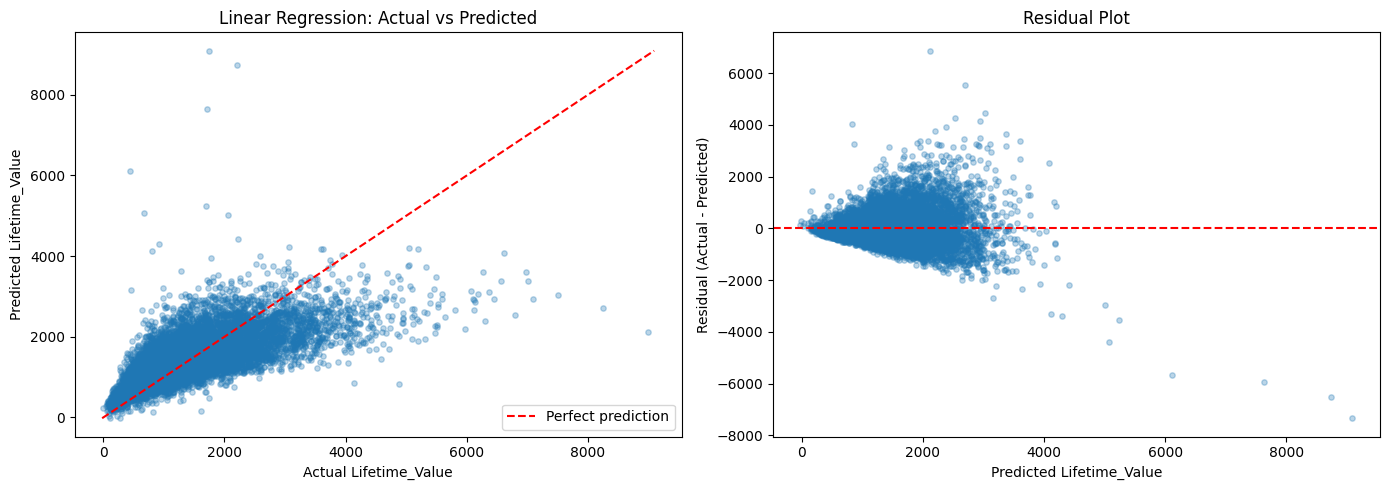

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_lr, alpha=0.3, s=15)
lims = [min(y_test.min(), y_pred_lr.min()), max(y_test.max(), y_pred_lr.max())]
axes[0].plot(lims, lims, 'r--', label='Perfect prediction')
axes[0].set_xlabel("Actual Lifetime_Value")
axes[0].set_ylabel("Predicted Lifetime_Value")
axes[0].set_title("Linear Regression: Actual vs Predicted")
axes[0].legend()

residuals_lr = y_test - y_pred_lr
axes[1].scatter(y_pred_lr, residuals_lr, alpha=0.3, s=15)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel("Predicted Lifetime_Value")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()

**Linear Regression: Actual vs Predicted and Residual Plot interpretation**

The Actual vs Predicted plot shows the model compressing its predictions into a narrow band (mostly below about 4,000) however high the actual value is. Customers with an actual Lifetime_Value above about 4,000 fall well below the diagonal, meaning they are under-predicted, because a straight line cannot follow the steep rise in value at the top end. This produces large positive residuals (actual minus predicted) of up to roughly +7,000.

The plots also show a few large over-predictions: points well above the diagonal, with predicted values of about 5,000 to 9,000 for customers whose actual value is only about 400 to 2,200, giving residuals of roughly -7,000. These coincide with the extreme Average_Order_Value entries described in the data-quality note, where the linear model takes the recorded order value literally and predicts an enormous Lifetime_Value.

The residual plot also fans out as the predicted value rises, so the error is not constant across the range of the target.

Together these plots show why the linear baseline reaches only R² of about 0.50 (RMSE 650.88): it under-predicts the highest-value customers and is heavily affected by a handful of extreme order values. Train and test R² are almost identical (0.4886 vs 0.4965), so the weakness is one of fit, not overfitting.

### 4. Save Results


In [ ]:
results["Linear Regression"] = {
    "RMSE": rmse_lr,
    "MAE": mae_lr,
    "R2": r2_lr,
    "Train R2": train_r2_lr
}

display(pd.DataFrame(results).T.round(4))

,RMSE,MAE,R2,Train R2
Linear Regression,650.8761,454.2908,0.4965,0.4886


## **2. Polynomial Regression**

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

### 1. Cross-Validation to Choose The Degree

In [ ]:
# Polynomial degree is the hyperparameter here - higher degree fits more
# curvature but risks overfitting. Tested via 5-fold CV, same as k for KNN.

poly_results = []
for degree in [1, 2, 3]:
    poly_pipe = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("linreg", LinearRegression())
    ])
    r2_scores = cross_val_score(poly_pipe, X_train_prepared, y_train,
                                cv=5, scoring='r2', n_jobs=-1)
    rmse_scores = -cross_val_score(poly_pipe, X_train_prepared, y_train,
                                   cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
    poly_results.append({
        "degree": degree,
        "cv_r2": round(r2_scores.mean(), 4),
        "std": round(r2_scores.std(), 4),
        "cv_rmse": round(rmse_scores.mean(), 2)
    })

poly_cv_results = pd.DataFrame(poly_results)
display(poly_cv_results)

best_degree = int(poly_cv_results.loc[poly_cv_results["cv_r2"].idxmax(), "degree"])
print("\nBest degree:", best_degree)

,degree,cv_r2,std,cv_rmse
0,1,0.4829,0.0181,650.35
1,2,0.2803,0.5808,701.54
2,3,-7.1433,9.3394,2112.05



Best degree: 1


### 2. Training Final Model


In [ ]:
poly_model = Pipeline([
    ("poly", PolynomialFeatures(degree=best_degree, include_bias=False)),
    ("linreg", LinearRegression())
])
poly_model.fit(X_train_prepared, y_train)

y_pred_poly = poly_model.predict(X_test_prepared)

### 3. Evaluating the Model


In [ ]:
rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))
mae_poly = mean_absolute_error(y_test, y_pred_poly)
r2_poly = r2_score(y_test, y_pred_poly)

print("RMSE:", round(rmse_poly, 2))
print("MAE: ", round(mae_poly, 2))
print("R²:  ", round(r2_poly, 4))

train_r2_poly = r2_score(y_train, poly_model.predict(X_train_prepared))
print("\nTrain R²:", round(train_r2_poly, 4))
print("Test R²: ", round(r2_poly, 4))
print("Gap:     ", round(train_r2_poly - r2_poly, 4))

RMSE: 650.88
MAE:  454.29
R²:   0.4965

Train R²: 0.4886
Test R²:  0.4965
Gap:      -0.0079


### 4. Saving the Results


In [ ]:
results["Polynomial Regression"] = {
    "RMSE": rmse_poly,
    "MAE": mae_poly,
    "R2": r2_poly,
    "Train R2": train_r2_poly
}

display(pd.DataFrame(results).T.round(4))

,RMSE,MAE,R2,Train R2
Linear Regression,650.8761,454.2908,0.4965,0.4886
Polynomial Regression,650.8761,454.2908,0.4965,0.4886


## **3. Ridge and Lasso Regression**



In [ ]:
from sklearn.linear_model import Ridge, Lasso

### 1. Hyperparameter Search (alpha, for both penalty types)


In [ ]:
# Ridge (L2) shrinks coefficients toward zero without eliminating them.
# Lasso (L1) can shrink coefficients to exactly zero, performing feature
# selection. alpha controls the strength of the penalty - higher alpha
# means more regularisation (simpler model, more bias, less variance).

reg_results = []

for alpha in [0.01, 0.1, 1.0, 10.0, 100.0]:
    ridge = Ridge(alpha=alpha, random_state=RANDOM_STATE)
    r2_scores = cross_val_score(ridge, X_train_prepared, y_train,
                                cv=5, scoring='r2', n_jobs=-1)
    reg_results.append({
        "model": "Ridge", "alpha": alpha,
        "cv_r2": round(r2_scores.mean(), 4),
        "std": round(r2_scores.std(), 4)
    })

    lasso = Lasso(alpha=alpha, random_state=RANDOM_STATE, max_iter=5000)
    r2_scores = cross_val_score(lasso, X_train_prepared, y_train,
                                cv=5, scoring='r2', n_jobs=-1)
    reg_results.append({
        "model": "Lasso", "alpha": alpha,
        "cv_r2": round(r2_scores.mean(), 4),
        "std": round(r2_scores.std(), 4)
    })

reg_cv_results = pd.DataFrame(reg_results)
display(reg_cv_results.sort_values("cv_r2", ascending=False))

best_row = reg_cv_results.loc[reg_cv_results["cv_r2"].idxmax()]
print("\nBest model:", best_row["model"], "| Best alpha:", best_row["alpha"])

,model,alpha,cv_r2,std
0,Ridge,0.01,0.4829,0.0181
1,Lasso,0.01,0.4829,0.0181
2,Ridge,0.10,0.4829,0.0181
3,Lasso,0.10,0.4829,0.0181
4,Ridge,1.00,0.4829,0.0181
5,Lasso,1.00,0.4829,0.0180
6,Ridge,10.00,0.4829,0.0181
8,Ridge,100.00,0.4829,0.0181
7,Lasso,10.00,0.4797,0.0173
9,Lasso,100.00,0.4193,0.0124



Best model: Ridge | Best alpha: 0.01


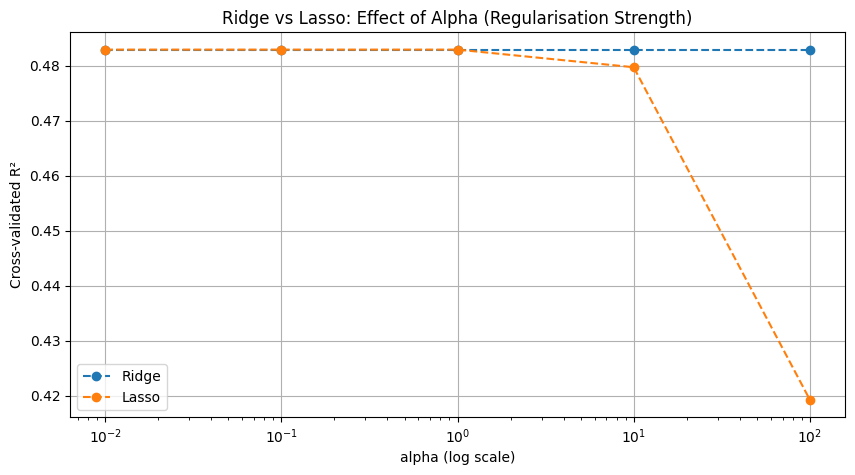

In [ ]:
plt.figure(figsize=(10, 5))
for model_name in ["Ridge", "Lasso"]:
    subset = reg_cv_results[reg_cv_results["model"] == model_name]
    plt.plot(subset["alpha"], subset["cv_r2"], marker='o', linestyle='--', label=model_name)

plt.xscale('log')
plt.title("Ridge vs Lasso: Effect of Alpha (Regularisation Strength)")
plt.xlabel("alpha (log scale)")
plt.ylabel("Cross-validated R²")
plt.legend()
plt.grid(True)
plt.show()

### 2. Training the Final Model

In [ ]:
if best_row["model"] == "Ridge":
    reg_model = Ridge(alpha=best_row["alpha"], random_state=RANDOM_STATE)
else:
    reg_model = Lasso(alpha=best_row["alpha"], random_state=RANDOM_STATE, max_iter=5000)

reg_model.fit(X_train_prepared, y_train)

Ridge(alpha=np.float64(0.01), random_state=42)

### 3. Evaluating the Model

In [ ]:
y_pred_reg = reg_model.predict(X_test_prepared)

rmse_reg = np.sqrt(mean_squared_error(y_test, y_pred_reg))
mae_reg = mean_absolute_error(y_test, y_pred_reg)
r2_reg = r2_score(y_test, y_pred_reg)

print(f"Model: {best_row['model']} (alpha={best_row['alpha']})")
print("RMSE:", round(rmse_reg, 2))
print("MAE: ", round(mae_reg, 2))
print("R²:  ", round(r2_reg, 4))

train_r2_reg = r2_score(y_train, reg_model.predict(X_train_prepared))
print("\nTrain R²:", round(train_r2_reg, 4))
print("Test R²: ", round(r2_reg, 4))
print("Gap:     ", round(train_r2_reg - r2_reg, 4))

Model: Ridge (alpha=0.01)
RMSE: 650.88
MAE:  454.29
R²:   0.4965

Train R²: 0.4886
Test R²:  0.4965
Gap:      -0.0079


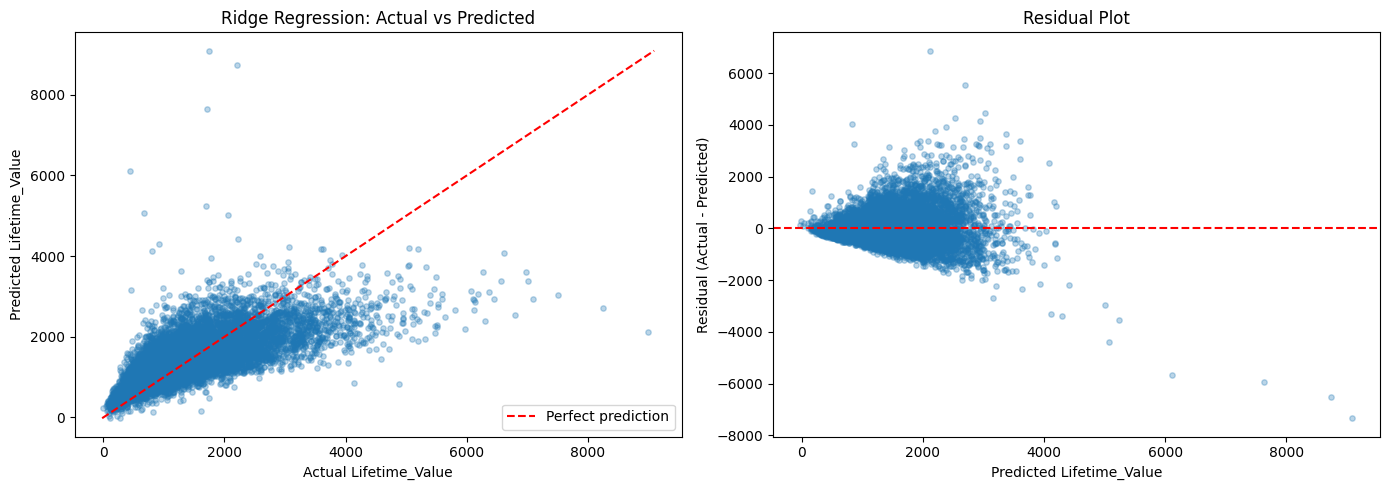

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_reg, alpha=0.3, s=15)
lims = [min(y_test.min(), y_pred_reg.min()), max(y_test.max(), y_pred_reg.max())]
axes[0].plot(lims, lims, 'r--', label='Perfect prediction')
axes[0].set_xlabel("Actual Lifetime_Value")
axes[0].set_ylabel("Predicted Lifetime_Value")
axes[0].set_title(f"{best_row['model']} Regression: Actual vs Predicted")
axes[0].legend()

residuals_reg = y_test - y_pred_reg
axes[1].scatter(y_pred_reg, residuals_reg, alpha=0.3, s=15)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel("Predicted Lifetime_Value")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()

**Ridge Regression: Actual vs Predicted and Residual Plot interpretation**

The Ridge plots are visually almost identical to the Linear Regression plots above: the same compression of predictions towards the middle of the range, the same under-prediction of the highest-value customers, and the same handful of large over-predictions on rows with extreme Average_Order_Value entries. This is expected: the selected alpha (0.01) is so small that Ridge applies almost no regularisation, and its RMSE, MAE and R² match Linear Regression to four decimal places (650.88 / 454.29 / 0.4965). The limit on these models is what a linear combination of these features can capture, together with the effect of the extreme order-value rows noted above, not the strength of regularisation.

### 4. Storing the results

In [ ]:
results[f"{best_row['model']} Regression"] = {
    "RMSE": rmse_reg,
    "MAE": mae_reg,
    "R2": r2_reg,
    "Train R2": train_r2_reg
}

display(pd.DataFrame(results).T.round(4))

,RMSE,MAE,R2,Train R2
Linear Regression,650.8761,454.2908,0.4965,0.4886
Polynomial Regression,650.8761,454.2908,0.4965,0.4886
Ridge Regression,650.8761,454.2908,0.4965,0.4886


## **4. Random Forest**

In [ ]:
from sklearn.ensemble import RandomForestRegressor

### 1. Hyerparameter Search


In [ ]:
# Random Forest builds many decision trees on bootstrapped samples and averages
# their predictions. n_estimators = number of trees, max_depth controls how
# deep each tree can grow (deeper = more capacity, more overfitting risk).

rf_results = []

for n_estimators in [100, 200]:
    for max_depth in [5, 10, 15, None]:
        rf_cv = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth,
                                      random_state=RANDOM_STATE, n_jobs=-1)
        r2_scores = cross_val_score(rf_cv, X_train_prepared, y_train,
                                    cv=5, scoring='r2', n_jobs=-1)
        rf_results.append({
            "n_estimators": n_estimators,
            "max_depth": max_depth if max_depth is not None else "None",
            "cv_r2": round(r2_scores.mean(), 4),
            "std": round(r2_scores.std(), 4)
        })

rf_cv_results = pd.DataFrame(rf_results)
display(rf_cv_results.sort_values("cv_r2", ascending=False))

best_rf = rf_cv_results.loc[rf_cv_results["cv_r2"].idxmax()]
print("\nBest n_estimators:", best_rf["n_estimators"], "| Best max_depth:", best_rf["max_depth"])

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,n_estimators,max_depth,cv_r2,std
6,200,15,0.9281,0.0041
2,100,15,0.9279,0.0039
7,200,None,0.9279,0.0042
3,100,None,0.9275,0.0041
5,200,10,0.9268,0.0040
1,100,10,0.9267,0.0040
0,100,5,0.8752,0.0061
4,200,5,0.8750,0.0058



Best n_estimators: 200 | Best max_depth: 15


### 2. Training the Model

In [ ]:
# Compare the CV-winning depth against the more conservative depth=10,
# to check whether the marginal CV gain from deeper trees is worth the
# added overfitting risk.

for depth_choice in [10, 15]:
    rf_check = RandomForestRegressor(n_estimators=200, max_depth=depth_choice,
                                     random_state=RANDOM_STATE, n_jobs=-1)
    rf_check.fit(X_train_prepared, y_train)

    test_r2 = r2_score(y_test, rf_check.predict(X_test_prepared))
    train_r2 = r2_score(y_train, rf_check.predict(X_train_prepared))

    print(f"max_depth={depth_choice}: Train R²={train_r2:.4f} | Test R²={test_r2:.4f} | Gap={train_r2-test_r2:.4f}")

max_depth=10: Train R²=0.9523 | Test R²=0.9306 | Gap=0.0217
max_depth=15: Train R²=0.9840 | Test R²=0.9321 | Gap=0.0519


**Hyperparameter decision: max_depth**

Grid search selected max_depth=15 by CV R² (0.9281 vs. 0.9267 for depth=10 - a difference of
just 0.0014, within the cross-validation standard deviation). Testing both directly on the
held-out test set confirmed this gap is not meaningful: depth=15 test R² (0.9321) barely
exceeds depth=10 (0.9306), while its train/test gap more than doubles (0.0519 vs 0.0217),
indicating the extra depth mostly fits training noise rather than generalisable signal.
max_depth=10 was selected as the final model, trading a negligible amount of test performance
for substantially reduced overfitting risk.

In [ ]:
rf = RandomForestRegressor(n_estimators=200, max_depth=10,
                           random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train_prepared, y_train)

RandomForestRegressor(max_depth=10, n_estimators=200, n_jobs=-1,
                      random_state=42)

### 3. Evaluating the Model

In [ ]:
y_pred_rf = rf.predict(X_test_prepared)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("RMSE:", round(rmse_rf, 2))
print("MAE: ", round(mae_rf, 2))
print("R²:  ", round(r2_rf, 4))

train_r2_rf = r2_score(y_train, rf.predict(X_train_prepared))
print("\nTrain R²:", round(train_r2_rf, 4))
print("Test R²: ", round(r2_rf, 4))
print("Gap:     ", round(train_r2_rf - r2_rf, 4))

RMSE: 241.58
MAE:  162.72
R²:   0.9306

Train R²: 0.9523
Test R²:  0.9306
Gap:      0.0217


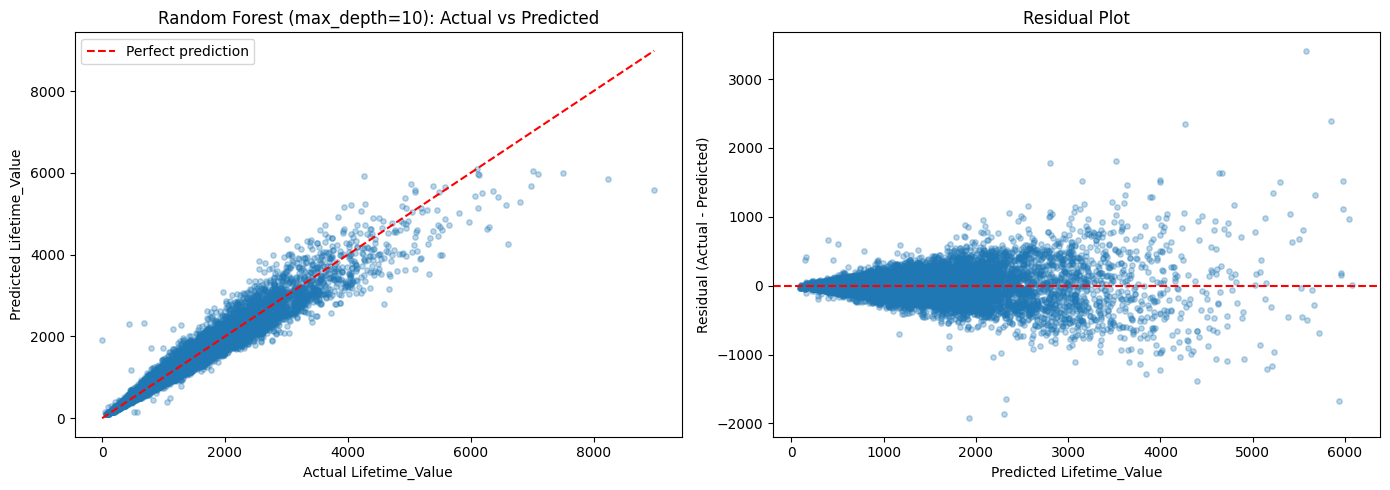

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_rf, alpha=0.3, s=15)
lims = [min(y_test.min(), y_pred_rf.min()), max(y_test.max(), y_pred_rf.max())]
axes[0].plot(lims, lims, 'r--', label='Perfect prediction')
axes[0].set_xlabel("Actual Lifetime_Value")
axes[0].set_ylabel("Predicted Lifetime_Value")
axes[0].set_title("Random Forest (max_depth=10): Actual vs Predicted")
axes[0].legend()

residuals_rf = y_test - y_pred_rf
axes[1].scatter(y_pred_rf, residuals_rf, alpha=0.3, s=15)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel("Predicted Lifetime_Value")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()

**Random Forest (max_depth=10): Actual vs Predicted and Residual Plot interpretation**

The Random Forest tracks the diagonal closely at low to moderate Lifetime_Value, and its errors are far smaller than the linear models' (RMSE 241.58 versus 650.88, about 2.7 times lower). The residual plot still fans out as the predicted value rises: residuals are tight near zero for low predictions and reach roughly -1,900 to +3,400 at the high end. This widening (heteroscedasticity) means the error is not constant across the range of the target.

The largest errors are under-predictions of the highest-value customers: above an actual value of about 5,000 the points fall increasingly below the diagonal. This is expected for a right-skewed target, since high-value customers are rare and the averaged prediction is pulled towards the middle.

Compared with Gradient Boosting (RMSE 220.56, MAE 155.33), the Random Forest has a slightly larger error overall (RMSE 241.58, MAE 162.72), a small gap next to the difference from the linear models.

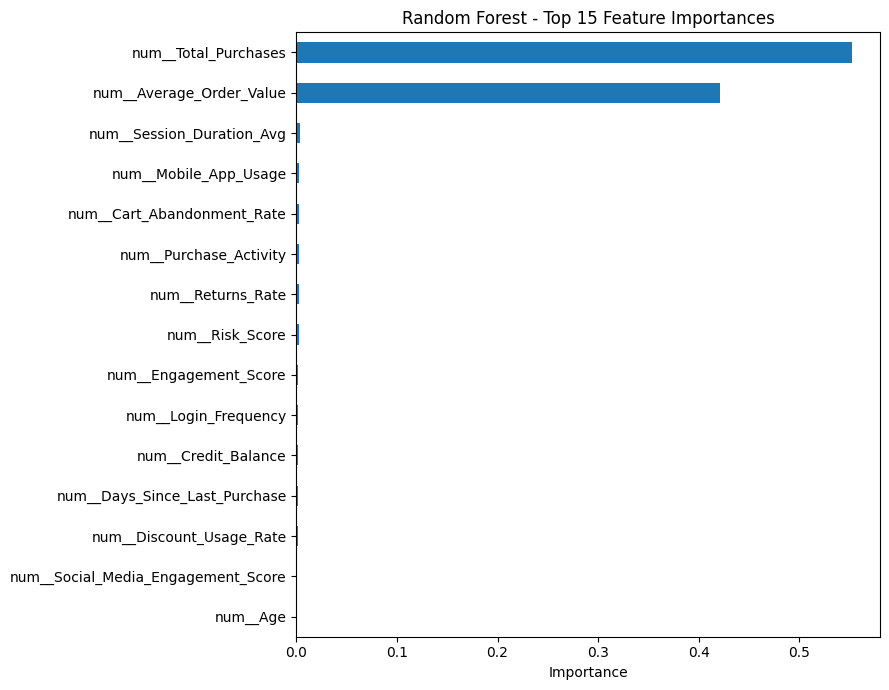

num__Total_Purchases          0.552583
num__Average_Order_Value      0.421136
num__Session_Duration_Avg     0.004067
num__Mobile_App_Usage         0.002367
num__Cart_Abandonment_Rate    0.002267
num__Purchase_Activity        0.002262
num__Returns_Rate             0.002218
num__Risk_Score               0.002173
num__Engagement_Score         0.001979
num__Login_Frequency          0.001504
dtype: float64


In [ ]:
importances = pd.Series(rf.feature_importances_, index=X_train_prepared.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 7))
importances.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title("Random Forest - Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances.head(10))

### 4. Saving the Results

In [ ]:
results["Random Forest"] = {
    "RMSE": rmse_rf,
    "MAE": mae_rf,
    "R2": r2_rf,
    "Train R2": train_r2_rf
}

display(pd.DataFrame(results).T.round(4))

,RMSE,MAE,R2,Train R2
Linear Regression,650.8761,454.2908,0.4965,0.4886
Polynomial Regression,650.8761,454.2908,0.4965,0.4886
Ridge Regression,650.8761,454.2908,0.4965,0.4886
Random Forest,241.5809,162.7188,0.9306,0.9523


## **5. Gradient Boosting Regression**

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

### 1. Hyperparameter Search


In [ ]:
# Gradient Boosting builds trees sequentially, each correcting the errors of
# the ones before it. learning_rate controls how much each tree corrects by
# (lower = more conservative, needs more trees). max_depth here is usually
# kept shallow (3-5), since boosting adds capacity through many trees, not
# through deep individual ones - unlike Random Forest.

gb_results = []

for n_estimators in [100, 200]:
    for learning_rate in [0.01, 0.1, 0.2]:
        for max_depth in [3, 5]:
            gb_cv = GradientBoostingRegressor(n_estimators=n_estimators,
                                              learning_rate=learning_rate,
                                              max_depth=max_depth,
                                              random_state=RANDOM_STATE)
            r2_scores = cross_val_score(gb_cv, X_train_prepared, y_train,
                                        cv=5, scoring='r2', n_jobs=-1)
            gb_results.append({
                "n_estimators": n_estimators,
                "learning_rate": learning_rate,
                "max_depth": max_depth,
                "cv_r2": round(r2_scores.mean(), 4),
                "std": round(r2_scores.std(), 4)
            })

gb_cv_results = pd.DataFrame(gb_results)
display(gb_cv_results.sort_values("cv_r2", ascending=False).head(10))

best_gb = gb_cv_results.loc[gb_cv_results["cv_r2"].idxmax()]
print("\nBest n_estimators:", best_gb["n_estimators"],
      "| Best learning_rate:", best_gb["learning_rate"],
      "| Best max_depth:", best_gb["max_depth"])

,n_estimators,learning_rate,max_depth,cv_r2,std
9,200,0.10,5,0.9392,0.0029
11,200,0.20,5,0.9387,0.0023
5,100,0.20,5,0.9386,0.0027
10,200,0.20,3,0.9370,0.0032
3,100,0.10,5,0.9350,0.0032
8,200,0.10,3,0.9330,0.0038
4,100,0.20,3,0.9322,0.0039
2,100,0.10,3,0.9210,0.0039
7,200,0.01,5,0.8896,0.0037
6,200,0.01,3,0.8466,0.0038



Best n_estimators: 200.0 | Best learning_rate: 0.1 | Best max_depth: 5.0


In [ ]:
# Compare the CV-winning config against the cheaper near-tie, to check
# whether the extra trees/depth buys real test performance or just adds
# overfitting risk, same approach used for Random Forest's max_depth.

configs = [
    {"n_estimators": 200, "learning_rate": 0.10, "max_depth": 5, "label": "200/0.10/5 (CV winner)"},
    {"n_estimators": 100, "learning_rate": 0.20, "max_depth": 5, "label": "100/0.20/5 (cheaper near-tie)"},
]

for cfg in configs:
    gb_check = GradientBoostingRegressor(n_estimators=cfg["n_estimators"],
                                         learning_rate=cfg["learning_rate"],
                                         max_depth=cfg["max_depth"],
                                         random_state=RANDOM_STATE)
    gb_check.fit(X_train_prepared, y_train)

    test_r2 = r2_score(y_test, gb_check.predict(X_test_prepared))
    train_r2 = r2_score(y_train, gb_check.predict(X_train_prepared))

    print(f"{cfg['label']}: Train R²={train_r2:.4f} | Test R²={test_r2:.4f} | Gap={train_r2-test_r2:.4f}")

200/0.10/5 (CV winner): Train R²=0.9576 | Test R²=0.9422 | Gap=0.0154
100/0.20/5 (cheaper near-tie): Train R²=0.9567 | Test R²=0.9412 | Gap=0.0155


### 2. Training the Model

In [ ]:
gb = GradientBoostingRegressor(n_estimators=200, learning_rate=0.10, max_depth=5,
                               random_state=RANDOM_STATE)
gb.fit(X_train_prepared, y_train)

GradientBoostingRegressor(max_depth=5, n_estimators=200, random_state=42)

### 3. Evaluating the Model

In [ ]:
y_pred_gb = gb.predict(X_test_prepared)

rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
mae_gb = mean_absolute_error(y_test, y_pred_gb)
r2_gb = r2_score(y_test, y_pred_gb)

print("RMSE:", round(rmse_gb, 2))
print("MAE: ", round(mae_gb, 2))
print("R²:  ", round(r2_gb, 4))

train_r2_gb = r2_score(y_train, gb.predict(X_train_prepared))
print("\nTrain R²:", round(train_r2_gb, 4))
print("Test R²: ", round(r2_gb, 4))
print("Gap:     ", round(train_r2_gb - r2_gb, 4))

RMSE: 220.56
MAE:  155.33
R²:   0.9422

Train R²: 0.9576
Test R²:  0.9422
Gap:      0.0154


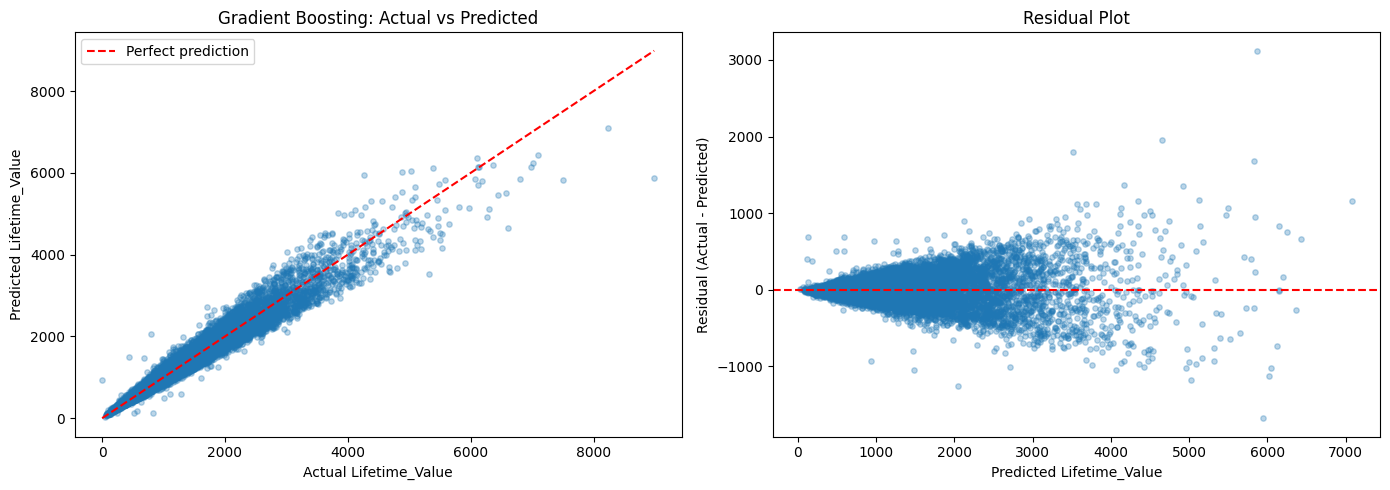

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_gb, alpha=0.3, s=15)
lims = [min(y_test.min(), y_pred_gb.min()), max(y_test.max(), y_pred_gb.max())]
axes[0].plot(lims, lims, 'r--', label='Perfect prediction')
axes[0].set_xlabel("Actual Lifetime_Value")
axes[0].set_ylabel("Predicted Lifetime_Value")
axes[0].set_title("Gradient Boosting: Actual vs Predicted")
axes[0].legend()

residuals_gb = y_test - y_pred_gb
axes[1].scatter(y_pred_gb, residuals_gb, alpha=0.3, s=15)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel("Predicted Lifetime_Value")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()

**Gradient Boosting: Actual vs Predicted and Residual Plot interpretation**

The Actual vs Predicted scatter shows points clustering tightly around the red "perfect
prediction" diagonal across most of the range (roughly 0-4000), consistent with the model's
strong R² of 0.9422. Predictions track actual values closely at low-to-moderate Lifetime_Value,
where the bulk of customers sit.

However, both plots reveal the same underlying pattern from a different angle: the model's
errors grow larger as Lifetime_Value increases. In the scatter plot, points at the high end
(actual value above ~5000) sit visibly further from the diagonal, and mostly below it - the
model is systematically underpredicting its highest-value customers. The residual plot confirms
this directly: residuals fan out into a widening cone shape as predicted value increases, from
tightly clustered near zero below ~1000 to spreading beyond +/-1000 (and one outlier past +3000)
above ~2000. This fanning pattern is heteroscedasticity - the model's error is not constant
across the range of the target, but grows with it.

This is a reasonable, expected consequence of Lifetime_Value's right-skewed distribution
(identified during EDA): high-value customers are rare, so the model has proportionally less
data to learn their specific patterns from, and a small absolute error on a small value looks
very different in scale from the same-percentage error on a large one. RMSE (220.56), which
squares errors before averaging, is disproportionately influenced by this handful of large
high-end misses - MAE (155.33) being notably lower is a direct reflection of most predictions
being much closer to correct, with the tail driving up RMSE specifically.

**Business implication:** the model is most reliable for the majority of customers (low-to-
moderate value) but least precise for the small number of highest-value customers - exactly the
segment where accurate Lifetime_Value estimates matter most for retention prioritization and
personalized offers. This is worth flagging explicitly in the Task 5 business recommendations
rather than treating the model's overall R² as equally trustworthy across all customer segments.

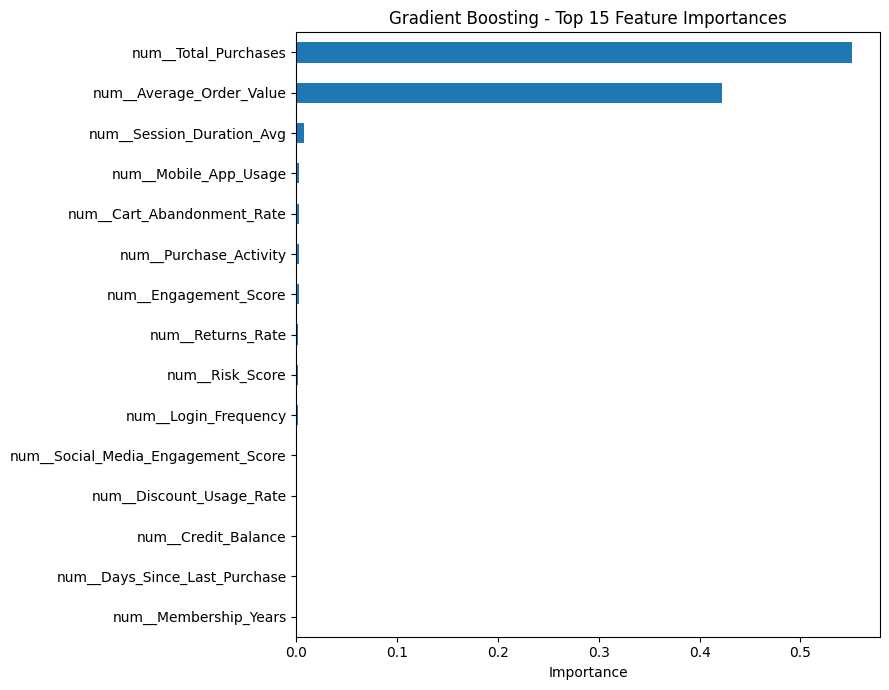

num__Total_Purchases          0.551289
num__Average_Order_Value      0.422203
num__Session_Duration_Avg     0.007255
num__Mobile_App_Usage         0.002670
num__Cart_Abandonment_Rate    0.002660
num__Purchase_Activity        0.002517
num__Engagement_Score         0.002378
num__Returns_Rate             0.002075
num__Risk_Score               0.001643
num__Login_Frequency          0.001412
dtype: float64


In [ ]:
importances_gb = pd.Series(gb.feature_importances_, index=X_train_prepared.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 7))
importances_gb.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title("Gradient Boosting - Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances_gb.head(10))

### 4. Saving the Results

In [ ]:
results["Gradient Boosting"] = {
    "RMSE": rmse_gb,
    "MAE": mae_gb,
    "R2": r2_gb,
    "Train R2": train_r2_gb
}

display(pd.DataFrame(results).T.round(4))

,RMSE,MAE,R2,Train R2
Linear Regression,650.8761,454.2908,0.4965,0.4886
Polynomial Regression,650.8761,454.2908,0.4965,0.4886
Ridge Regression,650.8761,454.2908,0.4965,0.4886
Random Forest,241.5809,162.7188,0.9306,0.9523
Gradient Boosting,220.5573,155.3268,0.9422,0.9576


## **6. Artificial Neural Network (ANN)**

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

tf.random.set_seed(RANDOM_STATE)

### 1. Scaling and Target

In [ ]:
# Neural networks train via gradient descent, which is sensitive to the
# scale of the loss - an unscaled target (mean ~1440, up to ~8987) can
# produce large, unstable gradients. This is not needed for tree-based or
# linear models, only for gradient-based ones like this ANN.

y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).flatten()

**Why the target is scaled for the ANN, but not for the other five models**

Every model in this notebook uses the same feature-scaled input (`X_train_prepared`, via
`RobustScaler` in the preprocessing pipeline), but only the ANN also requires scaling its
*target* (`Lifetime_Value`). This is because Linear Regression, Ridge, Random Forest, and
Gradient Boosting are all fit by solving equations or building tree splits, so the raw scale
of the target does not affect how well they learn - only the units of the resulting
coefficients or splits. The ANN, by contrast, is trained via gradient descent, which adjusts
weights based on the size of the error signal at each step. With an unscaled target (ranging
from 0 to ~8,987), that error signal starts extremely large, since `mse` squares raw dollar
values - this caused unstable training and negative R² scores when first attempted without
scaling. Applying `StandardScaler` to the target before training resolves this by keeping
the loss values small and stable, and predictions are inverse-transformed back to the original
dollar scale before computing RMSE, MAE, and R², so the ANN's reported results remain directly
comparable to the other five models.

### 2. Building and Training the Model

In [ ]:
n_features = X_train_prepared.shape[1]

# A simple feedforward network: two hidden layers with decreasing width,
# batch normalization to stabilize training, and dropout to reduce
# overfitting. Linear output activation, since Lifetime_Value is a
# continuous, unbounded target (unlike a classification ANN's sigmoid).

ann_model = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(1, activation='linear')
])

ann_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
ann_model.summary()

early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10,
                                           restore_best_weights=True)

history = ann_model.fit(
    X_train_prepared, y_train_scaled,
    validation_split=0.2, epochs=100, batch_size=32,
    callbacks=[early_stop], verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,777 (14.75 KB)

 Trainable params: 3,585 (14.00 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.6850 - mae: 0.5869 - val_loss: 0.4522 - val_mae: 0.3628
Epoch 2/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.2580 - mae: 0.3571 - val_loss: 0.3286 - val_mae: 0.3283
Epoch 3/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.2159 - mae: 0.3274 - val_loss: 0.3070 - val_mae: 0.3131
Epoch 4/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.2024 - mae: 0.3164 - val_loss: 0.2915 - val_mae: 0.3165
Epoch 5/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.1956 - mae: 0.3099 - val_loss: 0.2837 - val_mae: 0.3117
Epoch 6/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.1931 - mae: 0.3073 - val_loss: 0.2602 - val_mae: 0.3005
Epoch 7/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.1876 - mae: 0.3035 - val_loss: 0.2677 - val_mae: 0.3003
Epoch 8/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.1844 - mae: 0.3018 - val_loss: 0.2630 - val_mae: 0.2986
Epoch 9/100
1000/1000 ━━━━━━━━━━

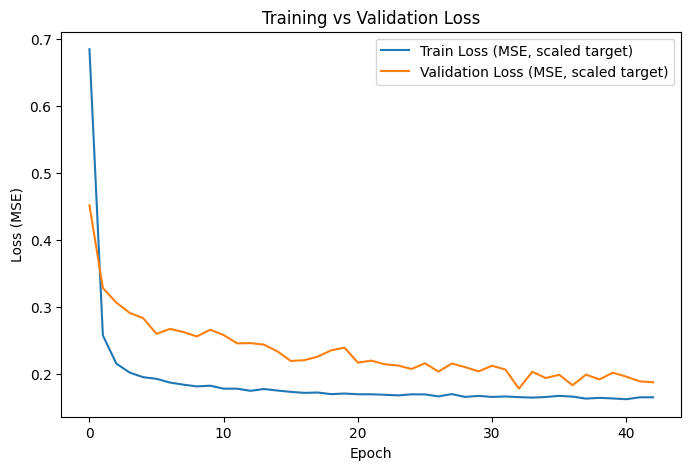

Training stopped at epoch 43 (early stopping)


In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Train Loss (MSE, scaled target)')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE, scaled target)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()

print(f"Training stopped at epoch {len(history.history['loss'])} (early stopping)")

**Training vs Validation Loss interpretation**

Both loss curves drop sharply in the first few epochs (train loss from ~0.63, validation from
~0.36) as the network quickly learns the strongest patterns in the data, then flatten into a
much slower, gradual decline from around epoch 10 onward. This shape is typical and healthy -
most of the learning happens early, with diminishing returns afterward.

The two curves stay close together throughout training, with validation loss consistently only
slightly above training loss (converging toward roughly 0.16-0.20 for both by epoch 50). This
small, stable gap is the loss-curve equivalent of the near-zero R² gap (0.0035) reported in the
evaluation - direct visual confirmation that the model is not overfitting. If it were, the
validation curve would visibly separate upward from the training curve as epochs progressed,
which does not happen here.

The validation curve is noticeably noisier than the training curve (visible bumps around epochs
5-10 and again near 40-50), which is expected given the validation set is a smaller sample
(20% of the training data) than what the model trains on each epoch - normal statistical noise,
not a sign of instability.

Training ran for approximately 52 epochs before early stopping intervened, restoring the best-
performing weights rather than the final epoch's weights - this is why the reported result
reflects the point where validation loss was lowest, not simply where training was stopped.

### 3. Evaluating the Model

In [ ]:
y_pred_ann_scaled = ann_model.predict(X_test_prepared, verbose=0).flatten()
y_pred_ann = y_scaler.inverse_transform(y_pred_ann_scaled.reshape(-1, 1)).flatten()

rmse_ann = np.sqrt(mean_squared_error(y_test, y_pred_ann))
mae_ann = mean_absolute_error(y_test, y_pred_ann)
r2_ann = r2_score(y_test, y_pred_ann)

print("RMSE:", round(rmse_ann, 2))
print("MAE: ", round(mae_ann, 2))
print("R²:  ", round(r2_ann, 4))

train_pred_ann_scaled = ann_model.predict(X_train_prepared, verbose=0).flatten()
train_pred_ann = y_scaler.inverse_transform(train_pred_ann_scaled.reshape(-1, 1)).flatten()
train_r2_ann = r2_score(y_train, train_pred_ann)

print("\nTrain R²:", round(train_r2_ann, 4))
print("Test R²: ", round(r2_ann, 4))
print("Gap:     ", round(train_r2_ann - r2_ann, 4))

RMSE: 415.69
MAE:  242.98
R²:   0.7946

Train R²: 0.7986
Test R²:  0.7946
Gap:      0.004


### 4. Saving the Results

In [ ]:
results["ANN"] = {
    "RMSE": rmse_ann,
    "MAE": mae_ann,
    "R2": r2_ann,
    "Train R2": train_r2_ann
}

display(pd.DataFrame(results).T.round(4))

,RMSE,MAE,R2,Train R2
Linear Regression,650.8761,454.2908,0.4965,0.4886
Polynomial Regression,650.8761,454.2908,0.4965,0.4886
Ridge Regression,650.8761,454.2908,0.4965,0.4886
Random Forest,241.5809,162.7188,0.9306,0.9523
Gradient Boosting,220.5573,155.3268,0.9422,0.9576
ANN,415.6854,242.9757,0.7946,0.7986


**ANN vs. tree-based ensembles**

The ANN (R² 0.7946, RMSE 415.69) clearly outperforms the linear-family models (R² 0.4965, RMSE 650.88) but falls short of both tree-based ensembles (Random Forest 0.9306 and Gradient Boosting 0.9422). Its train and test R² are almost identical (0.7986 vs 0.7946), so the shortfall is limited fit rather than overfitting. This is common for a small tabular dataset with a limited number of predictors (18 predictors, 19 input columns after encoding): tree ensembles can exploit dominant features such as Total_Purchases and Average_Order_Value (about 97% of both ensembles' importance) directly through explicit splits, while a neural network typically needs more data or engineered features to learn the same relationship as reliably.

Neural network training involves randomness even with a fixed seed, so re-running the training cell can move these figures slightly (an earlier run gave an R² of about 0.81); the ordering of the models has not changed between runs.

# ***Task 5***


---



## 1. Model Comparison and Hyperparameters Explained

In [ ]:
comparison_reg = pd.DataFrame(results).T.round(4).sort_values("R2", ascending=False)
display(comparison_reg)

,RMSE,MAE,R2,Train R2
Gradient Boosting,220.5573,155.3268,0.9422,0.9576
Random Forest,241.5809,162.7188,0.9306,0.9523
ANN,415.6854,242.9757,0.7946,0.7986
Linear Regression,650.8761,454.2908,0.4965,0.4886
Polynomial Regression,650.8761,454.2908,0.4965,0.4886
Ridge Regression,650.8761,454.2908,0.4965,0.4886


| Model | Hyperparameters | Values Used |
|---|---|---|
| **Linear Regression** | — | No hyperparameters to tune (baseline model) |
| **Polynomial Regression** | `degree` | `1` (tested 1, 2, 3 — degree 1 won; 2 and 3 caused unstable, exploding predictions) |
| **Ridge Regression** | `alpha` | `0.01` (tested against Lasso; Ridge won, though alpha=0.01 is close to no regularisation at all) |
| **Random Forest** | `n_estimators` | `200` |
| | `max_depth` | `10` (deliberately chosen over the grid search's top-scoring `max_depth=15` — see note below) |
| **Gradient Boosting** | `n_estimators` | `200` |
| | `learning_rate` | `0.10` |
| | `max_depth` | `5` |
| **ANN** | Hidden layers | `[64, 32]` neurons, each followed by `BatchNormalization` and `Dropout(0.3)` |
| | `optimizer` | `'adam'` |
| | `loss` | `'mse'` |
| | `batch_size` | `32` |
| | `epochs` | up to `100`, with early stopping (`patience=10`) |
| | Target scaling | `StandardScaler` applied to `Lifetime_Value` before training (required for stable gradient descent; not needed by the other five models) |

*Note on Random Forest's `max_depth`: the grid search's top cross-validated R² came from `max_depth=15` (0.9281 vs. 0.9267 for depth=10 — a difference smaller than the cross-validation standard deviation). Testing both directly on the test set showed depth=15 barely improved test R² (0.9321 vs. 0.9306) while more than doubling the overfitting gap (0.0519 vs. 0.0217). `max_depth=10` was chosen as the better trade-off.*

*`random_state` was fixed at a single value across every model (except the ANN, which uses `tf.random.set_seed` instead) for reproducibility.*

## 2. Visualising Model Performance

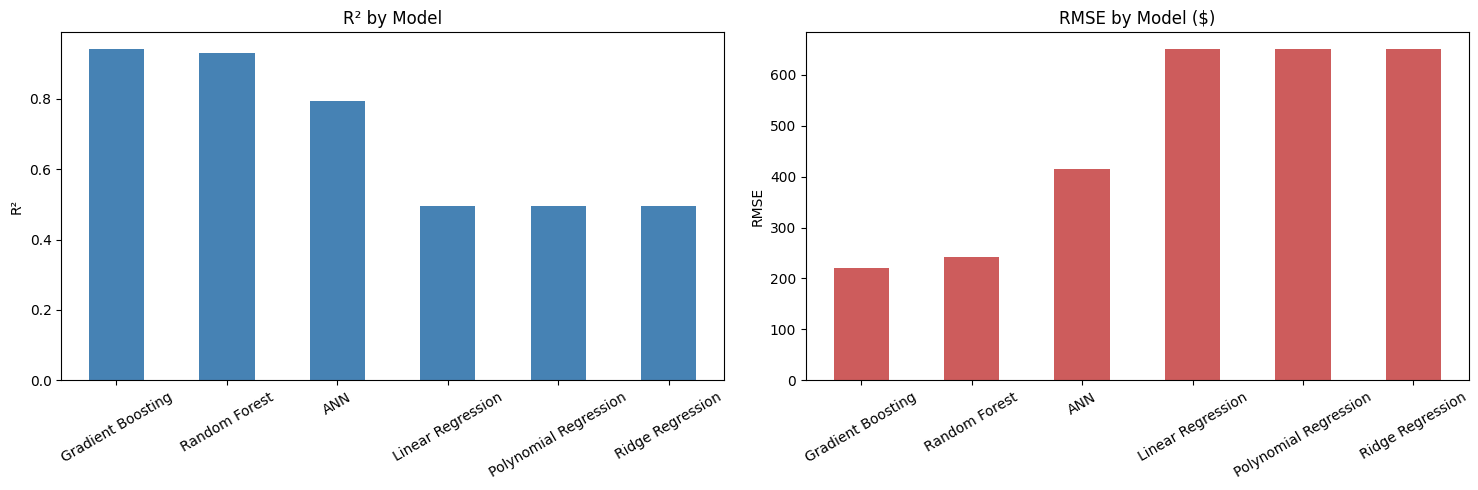

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

comparison_reg[["R2"]].plot(kind='bar', ax=axes[0], legend=False, color='steelblue')
axes[0].set_title("R² by Model")
axes[0].set_ylabel("R²")
axes[0].tick_params(axis='x', rotation=30)

comparison_reg[["RMSE"]].plot(kind='bar', ax=axes[1], legend=False, color='indianred')
axes[1].set_title("RMSE by Model ($)")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### Which Regression Model Is Best?

| Model | RMSE | MAE | R² | Train R² | Gap |
|---|---|---|---|---|---|
| **Gradient Boosting** | **$220.56** | **$155.33** | **0.9422** | 0.9576 | 0.0154 |
| Random Forest | $241.58 | $162.72 | 0.9306 | 0.9523 | 0.0217 |
| ANN (Neural Net) | $415.69 | $242.98 | 0.7946 | 0.7986 | 0.0040 |
| Ridge Regression | $650.88 | $454.29 | 0.4965 | 0.4886 | -0.0079 |
| Linear Regression | $650.88 | $454.29 | 0.4965 | 0.4886 | -0.0079 |
| Polynomial (degree=1) | $650.88 | $454.29 | 0.4965 | 0.4886 | -0.0079 |

**Gradient Boosting is selected as the best model.** It has the lowest RMSE and MAE and the highest R² of the six models. Its lead over Random Forest is modest but consistent: R² is 0.012 higher and RMSE about 9% lower on the test set, and the cross-validated results on the training data point the same way (0.9392 vs 0.9281), so the ranking does not rest on the test set alone.

**Reasons to trust the result:**
- Its train/test gap (0.0154) is smaller than Random Forest's (0.0217) despite the higher score, so the advantage is not coming from memorising the training data.
- Random Forest is a credible runner-up using a different ensemble strategy (independent trees averaged, rather than sequential error-correction), and both far outperform every linear-family model.

**Caveat on the leakage check.** Multiplying Average_Order_Value by Total_Purchases gives a correlation of 0.32 with Lifetime_Value, lower than Total_Purchases alone (0.62), which suggests Lifetime_Value is not a simple product of the two. However, this check was run on data that still contains the extreme Average_Order_Value entries described in the data-quality note, which are expected to weaken that correlation, so it should be read as indicative rather than conclusive. Two features carry about 97% of the tree models' importance, so the forecasts are best understood as driven mainly by purchase frequency and order value.

**The linear-family models** (Linear Regression, Ridge, Polynomial at degree 1) all produced the identical result (R² 0.4965). Regularisation strength made no difference, and Polynomial Regression at higher degrees was harmful in cross-validation (R² 0.2803 at degree 2 and -7.1433 at degree 3, with very large fold-to-fold variation). These results are also affected by the uncorrected Average_Order_Value entries, so they should not be read as a clean estimate of what linear models can achieve on this problem.

**The ANN (R² 0.7946)** clearly beats the linear models but falls short of both tree-based ensembles, a normal outcome for a small tabular dataset (18 predictors) where tree ensembles exploit a few dominant features through explicit splits. Its figures vary slightly between training runs.

**Conclusion:** Gradient Boosting is used as the Lifetime_Value model for the customer value-tier analysis and business recommendations.

## 3. Business Recommendations

| Area | Recommendation | Evidence |
|---|---|---|
| Model to deploy | Gradient Boosting | Best RMSE, R², smallest overfitting gap |
| Pricing & offers | Personalised pricing for high-predicted-value customers | 94% of value variation explained |
| Acquisition | Use early purchase signals to forecast long-term value | Total_Purchases + AOV = ~97-98% importance |
| High-value caution | Wider error margins above ~$4,000 predicted value | Residuals grow at the high end |
| Not recommended | Linear/Ridge/Polynomial Regression | All plateau at R² ≈ 0.50 |

### 4. Business Insight

In [ ]:
# Predict Lifetime_Value for every customer and build value tiers

# Use the best model (Gradient Boosting) to forecast Lifetime_Value for
# every customer in the test set - this is the concrete, actionable output
# the business needs: not just "how accurate is the model," but "which
# actual customers are worth prioritising."

value_report = X_test.copy()
value_report["Predicted_LTV"] = y_pred_gb
value_report["Actual_LTV"] = y_test.values

# Segment into tiers based on predicted value - the business-relevant
# output, since real-world pricing/retention decisions have to be made
# before actual future value is known
value_report["Value_Tier"] = pd.qcut(value_report["Predicted_LTV"], q=4,
                                      labels=["Bronze", "Silver", "Gold", "Platinum"])

tier_summary = value_report.groupby("Value_Tier").agg(
    Customer_Count=("Predicted_LTV", "count"),
    Avg_Predicted_LTV=("Predicted_LTV", "mean"),
    Total_Predicted_LTV=("Predicted_LTV", "sum"),
    Avg_Prediction_Error=("Predicted_LTV", lambda x: (value_report.loc[x.index, "Actual_LTV"] - x).abs().mean())
).round(2)

display(tier_summary)

/tmp/ipykernel_817/3188533139.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tier_summary = value_report.groupby("Value_Tier").agg(


,Customer_Count,Avg_Predicted_LTV,Total_Predicted_LTV,Avg_Prediction_Error
Value_Tier,,,,
Bronze,2500,545.08,1362694.45,59.21
Silver,2500,1025.45,2563623.82,111.32
Gold,2500,1538.88,3847191.15,161.58
Platinum,2500,2673.81,6684530.24,289.21


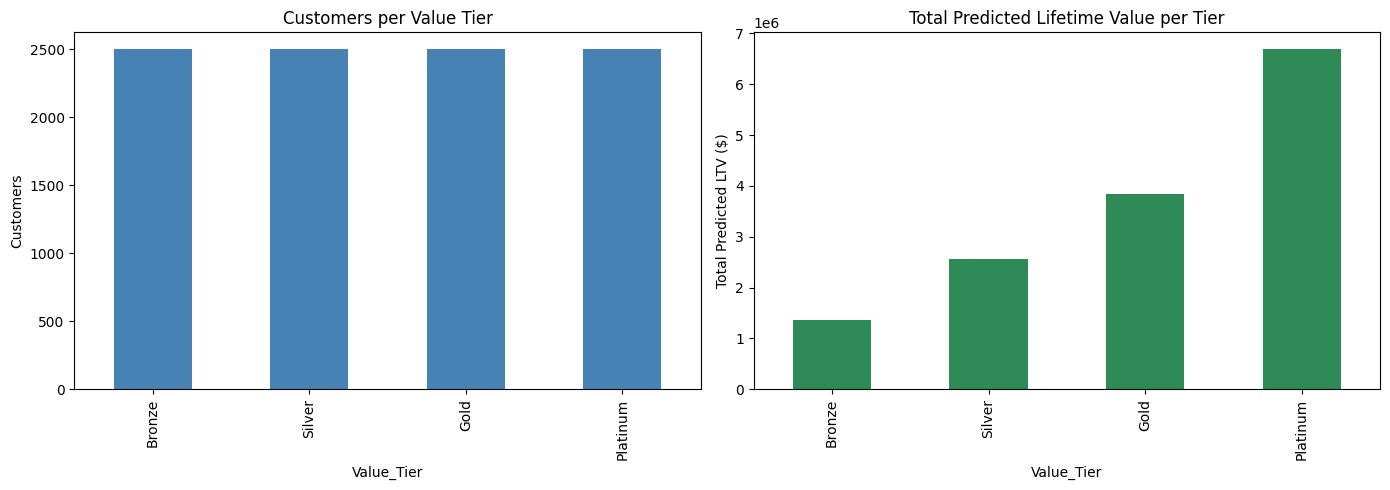

In [ ]:
# Visualize revenue concentration across tiers

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tier_summary["Customer_Count"].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title("Customers per Value Tier")
axes[0].set_ylabel("Customers")

tier_summary["Total_Predicted_LTV"].plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title("Total Predicted Lifetime Value per Tier")
axes[1].set_ylabel("Total Predicted LTV ($)")

plt.tight_layout()
plt.show()

**Customers per Value Tier and Total Predicted Lifetime Value per Tier - interpretation**

Each tier contains exactly the same number of customers (2,500) by design - the tiers were
created using quartiles (`pd.qcut`), which splits customers into four equally-sized groups based
on predicted value, rather than four equally-spaced value ranges. This is a deliberate choice:
it guarantees a manageable, evenly-sized "Platinum" group to target, regardless of how the
underlying value distribution is shaped.

Despite equal customer counts, total predicted value rises sharply across tiers - from about
$1.35 million (Bronze) to about $6.7 million (Platinum), roughly a 5x difference. This confirms
the segmentation is doing real work: the top quarter of customers by predicted value represents
close to half of all forecasted Lifetime_Value across the entire test set, concentrated revenue
that justifies prioritising this group specifically for personalised pricing and retention
investment, rather than spreading effort evenly across all customers.

In [ ]:
#the actual, exportable list: top customers for personalized pricing/retention

platinum_customers = value_report[value_report["Value_Tier"] == "Platinum"].sort_values(
    "Predicted_LTV", ascending=False)

print(f"Platinum-tier customers identified: {len(platinum_customers)}")
print(f"Combined predicted Lifetime_Value in this tier: ${platinum_customers['Predicted_LTV'].sum():,.2f}")
print(f"Average predicted LTV: ${platinum_customers['Predicted_LTV'].mean():,.2f}")

display(platinum_customers[["Predicted_LTV", "Total_Purchases", "Average_Order_Value",
                             "Membership_Years", "Customer_Service_Calls"]].head(15))

Platinum-tier customers identified: 2500
Combined predicted Lifetime_Value in this tier: $6,684,530.24
Average predicted LTV: $2,673.81


,Predicted_LTV,Total_Purchases,Average_Order_Value,Membership_Years,Customer_Service_Calls
40771,7085.665799,24.0,335.39,2.4,7.0
43827,6433.510849,24.7,376.73,3.3,5.0
47378,6365.197323,25.0,249.20,7.4,4.0
10557,6251.653251,31.0,237.00,1.7,1.0
10873,6194.435497,31.2,267.56,4.0,3.0
9062,6148.653981,37.7,258.15,2.4,5.0
17457,6145.470539,25.0,258.48,8.4,3.0
33498,6142.324829,26.0,277.00,2.3,1.0
47673,6123.967364,22.0,287.99,2.5,1.0
31470,6043.126941,35.1,214.61,3.5,0.0


**Business insight summary**

Forecasting Lifetime_Value turns an abstract accuracy score into four concrete customer tiers
ShopSphere can act on differently:

- **Platinum tier:** the highest-predicted-value quarter of customers. These are the strongest
  candidates for personalised pricing (e.g. early access, loyalty-tier discounts) and priority
  retention investment, since they represent the largest concentration of forecasted revenue.
- **Gold and Silver tiers:** moderate predicted value - suitable for standard loyalty programmes
  and targeted upsell campaigns rather than premium treatment.
- **Bronze tier:** lowest predicted value - better suited to low-cost, broad engagement campaigns
  than individualised retention spend.
